# PZT provisional calibrated analysis

**Working assumptions, not final validated experimental results.** Calibration
is user-confirmed: 5.05 micrometres/pixel and 25 microseconds. Source us/vs are
provisionally horizontal/vertical pixel displacements. Stored vertical sign
is retained, so U=+0.202 vs and V=+0.202 us. Exporter units, signs, upstream
replacement/smoothing and flag meanings remain unverified. No new filtering,
gap filling or extrapolation is applied. The image-reference origin is not
an established outlet. All result files live in provisional_calibrated.


In [1]:
from pathlib import Path
import sys, json
root=Path.cwd().resolve()
while not (root/'RAW_data').exists():
    if root==root.parent: raise RuntimeError('Workspace root not found')
    root=root.parent
sys.path.insert(0,str(root))
config_path=root/'PZT_Atomiser_Analysis/config/analysis.json'
config=json.loads(config_path.read_text())
print(json.dumps(config,indent=2))


{
  "conditions": [
    {
      "id": "Batch4_Cam1",
      "path": "RAW_data/Batch4_Cam1.h5"
    }
  ],
  "analysis_status": "provisional_calibrated",
  "components": [
    "us",
    "vs"
  ],
  "confirmed_spatial_calibration_um_per_pixel": 5.05,
  "confirmed_pulse_separation_seconds": 2.5e-05,
  "conditional_displacement_to_velocity_m_per_s_per_pixel": 0.202,
  "calibration_source": "User confirmation in this session; stored-array units remain unverified",
  "confirmed_physical_convention": {
    "U": "axial, positive upwards",
    "V": "transverse, positive rightwards",
    "axial_position_symbol": "x",
    "transverse_position_symbol": "y",
    "outlet_origin": "not established"
  },
  "conditional_image_displacement_mapping": {
    "U_m_per_s": "-0.202 * vertical_downward_pixel_displacement",
    "V_m_per_s": "+0.202 * horizontal_rightward_pixel_displacement"
  },
  "coordinate_scale": 0.00505,
  "coordinate_unit": "mm",
  "velocity_scale": 0.202,
  "velocity_unit": "m/s",
  "compo

In [2]:
from PZT_Atomiser_Analysis.analysis.pipeline import run
results=run(config_path)
output=root/config['output']


Calculating provisional finite-pair statistics: Batch4_Cam1


Independent station/flag and stored-mean checks passed.


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


...

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


Exported and validated 51 figures as PDF/SVG/600-dpi PNG plus NPZ in C:\Users\LabAdmin\OneDrive - Monash University\Desktop\Inhaler Project\PZT_droplets\PZT_Atomiser_Analysis\provisional_calibrated


## Methods and population

The reusable pipeline scales instantaneous components once, then computes
means, RMS, velocity magnitude and signed covariance from the same finite-pair population.
Denominator N is used. No flag is rejected. Flag-specific means/RMS are
selection-sensitivity diagnostics, not physically validated populations.
Full-range colour limits are shared across matching quantities and flag groups.
Profiles use native rows. Each station PDF is a distinct native-node empirical
distribution; histogram PDFs and exact empirical CDFs preserve sample support.
No independent-frame uncertainty or turbulence interpretation is claimed.
The primary velocity contours are the two mean components. In-plane velocity
magnitude plots are supplementary and are displayed separately below.


# Provisional calibrated results — not final validated experimental results

Spatial calibration 5.05 micrometres/pixel and pulse separation 25 microseconds
are confirmed by the user. Storage units, exported component definitions,
vertical sign and flag semantics are working assumptions, not independently
verified facts. The source arrays are us/vs because their means reproduce
exporter STATISTICS/U,V. Their upstream smoothing/replacement is undocumented.
No additional filtering, spatial smoothing, gap filling or extrapolation is
applied here.

For the current configuration, V=(0.202) us + (0) vs and U=(0) us + (0.202) vs in m/s. The factor
is applied exactly once to instantaneous arrays, and all moments are computed
from those samples. The stored vs sign is retained provisionally; upward spray
direction and decreasing exported y do not establish its sign. No ZNMF sign
reversal is inherited. Nearby original images lack an identifiable mapping to
these export vectors and do not independently resolve signs.

Coordinate convention: x is axial/upward, y is transverse/rightward; U and V
are the corresponding velocity components. Lowercase u' and v' denote their
fluctuations about the means. The instantaneous in-plane velocity vector is
bold u=(U,V). Its magnitude is sqrt(U squared + V squared). Magnitude of the
mean in-plane velocity vector is sqrt(mean(U) squared + mean(V) squared);
mean instantaneous in-plane velocity magnitude is mean(sqrt(U squared + V
squared)). These distinct quantities are supplementary; mean_U and mean_V
are the primary velocity contours in the notebook and report selection.

Horizontal plotted y is 0.00505 times exported PARAMETERS/x;
vertical plotted axial x is 0.00505 times exported PARAMETERS/y. Origin is the
exported (0,0) image reference, not an established outlet. Both coordinate
arrays retain alignment with native rows/columns. The scaled grid spacings
are 0.3232 mm horizontally and 0.0808 mm vertically; these are vector spacing,
not interrogation size or effective resolution.

The finite-pair population consists of samples with both us and vs finite.
No flag is selected or rejected. All moments, including velocity magnitude, covariance
and component RMS, use this paired population and population denominator N.
At least two pairs are required for reported moments. Correlation is masked
at zero variance. N and finite-pair fraction are not vector-validation or
concentration metrics. Code-specific counts/means/RMS are selection-sensitivity
diagnostics; no physical acceptance or rejection meanings are assigned.

Profiles follow selected native rows without shifting or interpolation.
Stations are configured exact nodes, not pooled spatial ROIs or a physical
centreline. Locations are shown on sampling_stations and in stations.csv.
Histogram PDFs use common bin edges per quantity across stations, full sample
support and unit integral. CDFs are exact empirical staircases. Normalized
fluctuations use local N-denominator RMS; zero variance is explicitly omitted.
No KDE or negative-velocity magnitude extrapolation is used. No independence-based
confidence intervals, turbulence interpretation or periodic/stochastic
decomposition are claimed. Timing beyond the pulse separation and tracked
phase remain unverified. First/middle/last numeric field keys are illustrative,
not phase-selected or certified typical fields.

Nonfinite samples, low-count statistics and zero-variance correlations are
masked. Contours use native quadrilaterals and corner_mask=False; intrinsic
contour-boundary interpolation does not increase measurement resolution.
Common full-range limits include flag populations when comparing component
mean/RMS, and all conditions. Instantaneous scales are common across selected
frames/conditions. Every figure has PDF, SVG, 600-dpi PNG and numerical NPZ;
spatial tables, station samples and verification vectors preserve underlying
values. No plot titles are used.

To revise definitions, edit config/analysis.json and rerun the notebook or CLI.
components chooses the source pair. component_mapping maps it into [V,U];
coordinate_mapping maps exported coordinates into [transverse,axial]. transform
is a common orthogonal basis change applied to BOTH coordinates and velocities.
A later basis reflection therefore also changes arrows and recomputed signed
covariance consistently. If evidence identifies an exporter-only component
sign mismatch with already-reflected coordinates, correct component_mapping
and document why coordinate_mapping differs. Do not reflect an already-correct
coordinate twice. All statistics, samples, profiles and captions regenerate.
No derivatives are computed in this run; any future derivatives must use this
same transformed Cartesian basis. General rotations turn row profiles into
oblique cuts: the pipeline rejects such row-profile geometry rather than
mislabeling it as constant axial position.

## Configuration used

- us/vs are horizontal/vertical pixel displacements per image pair; not independently verified. Their means reproduce STATISTICS/U,V.
- Exported coordinates are pixels, scaled once to mm; outlet origin is not established.
- Stored vs sign is retained provisionally; spray direction and descending y do not verify its sign.
- Use the finite-pair population without selecting flag codes. Flag-specific populations are diagnostics, not validated vectors.
- us/vs may include upstream smoothing or replacement; this analysis adds none. Relationship to u/v remains unverified.

Effective coordinate matrix: [[1.0, 0.0], [0.0, 1.0]]; effective component matrix: [[1.0, 0.0], [0.0, 1.0]].


## Primary mean-component contours

mean_U


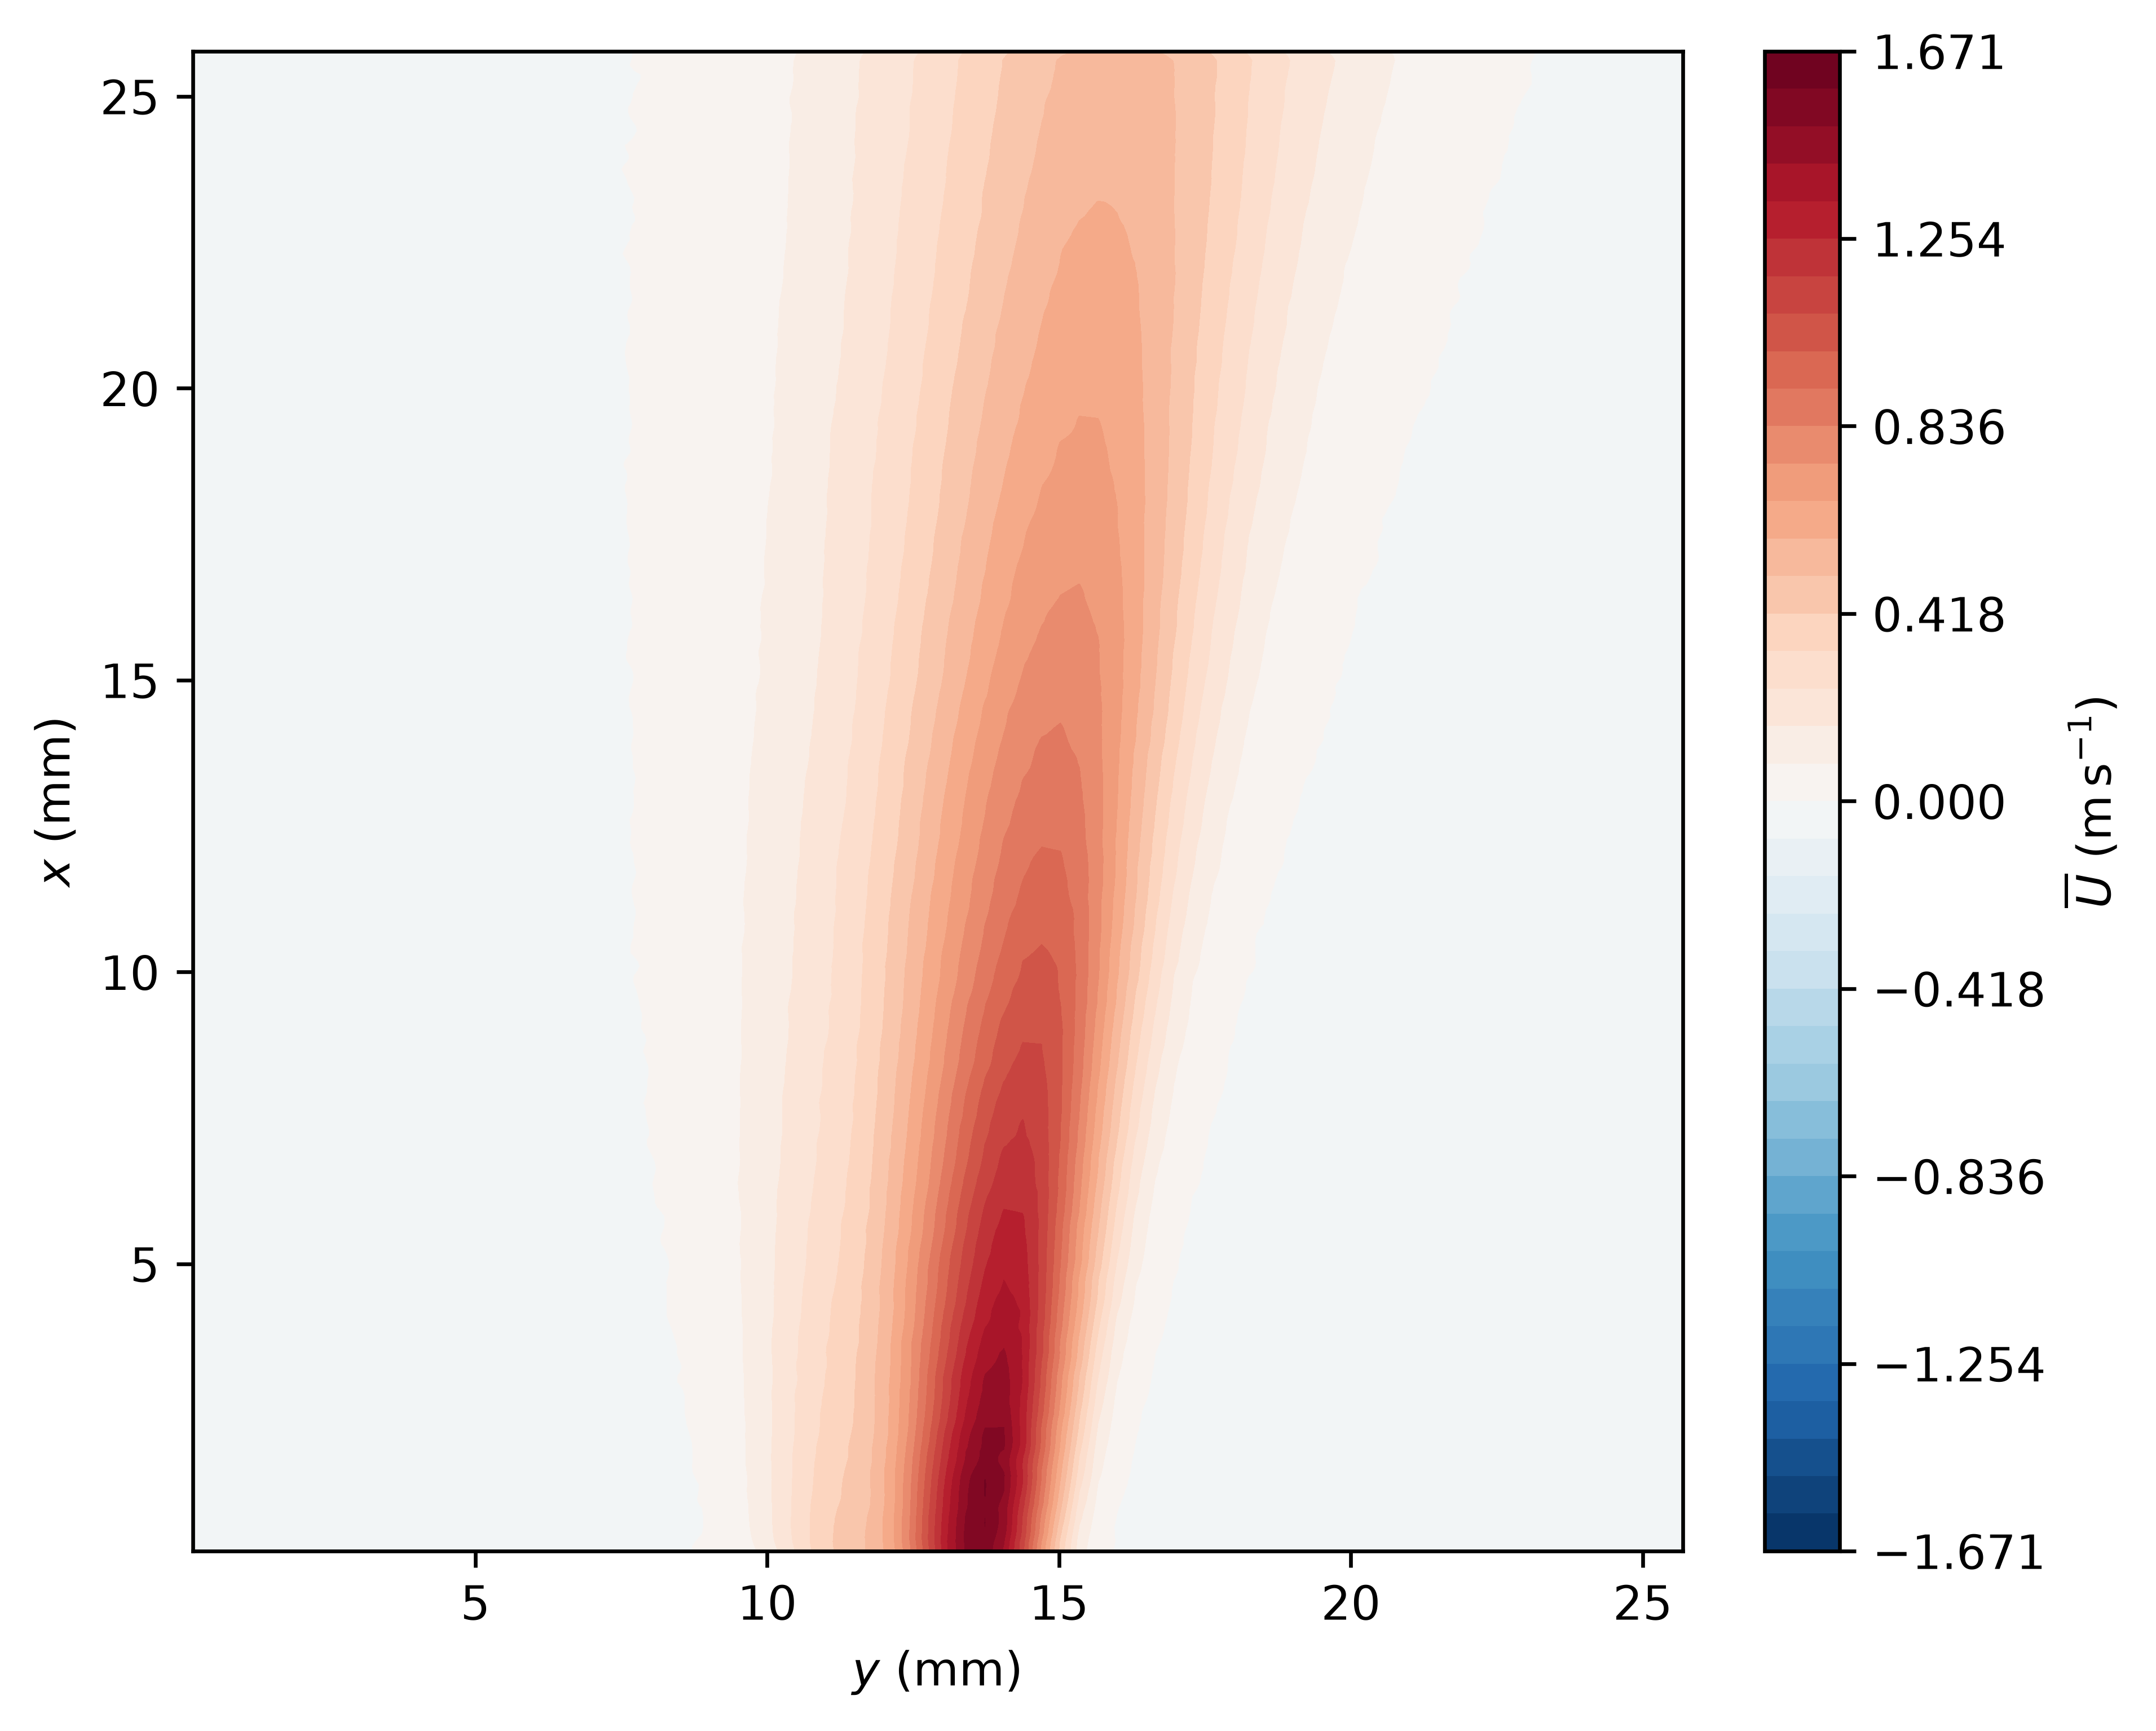

mean_V


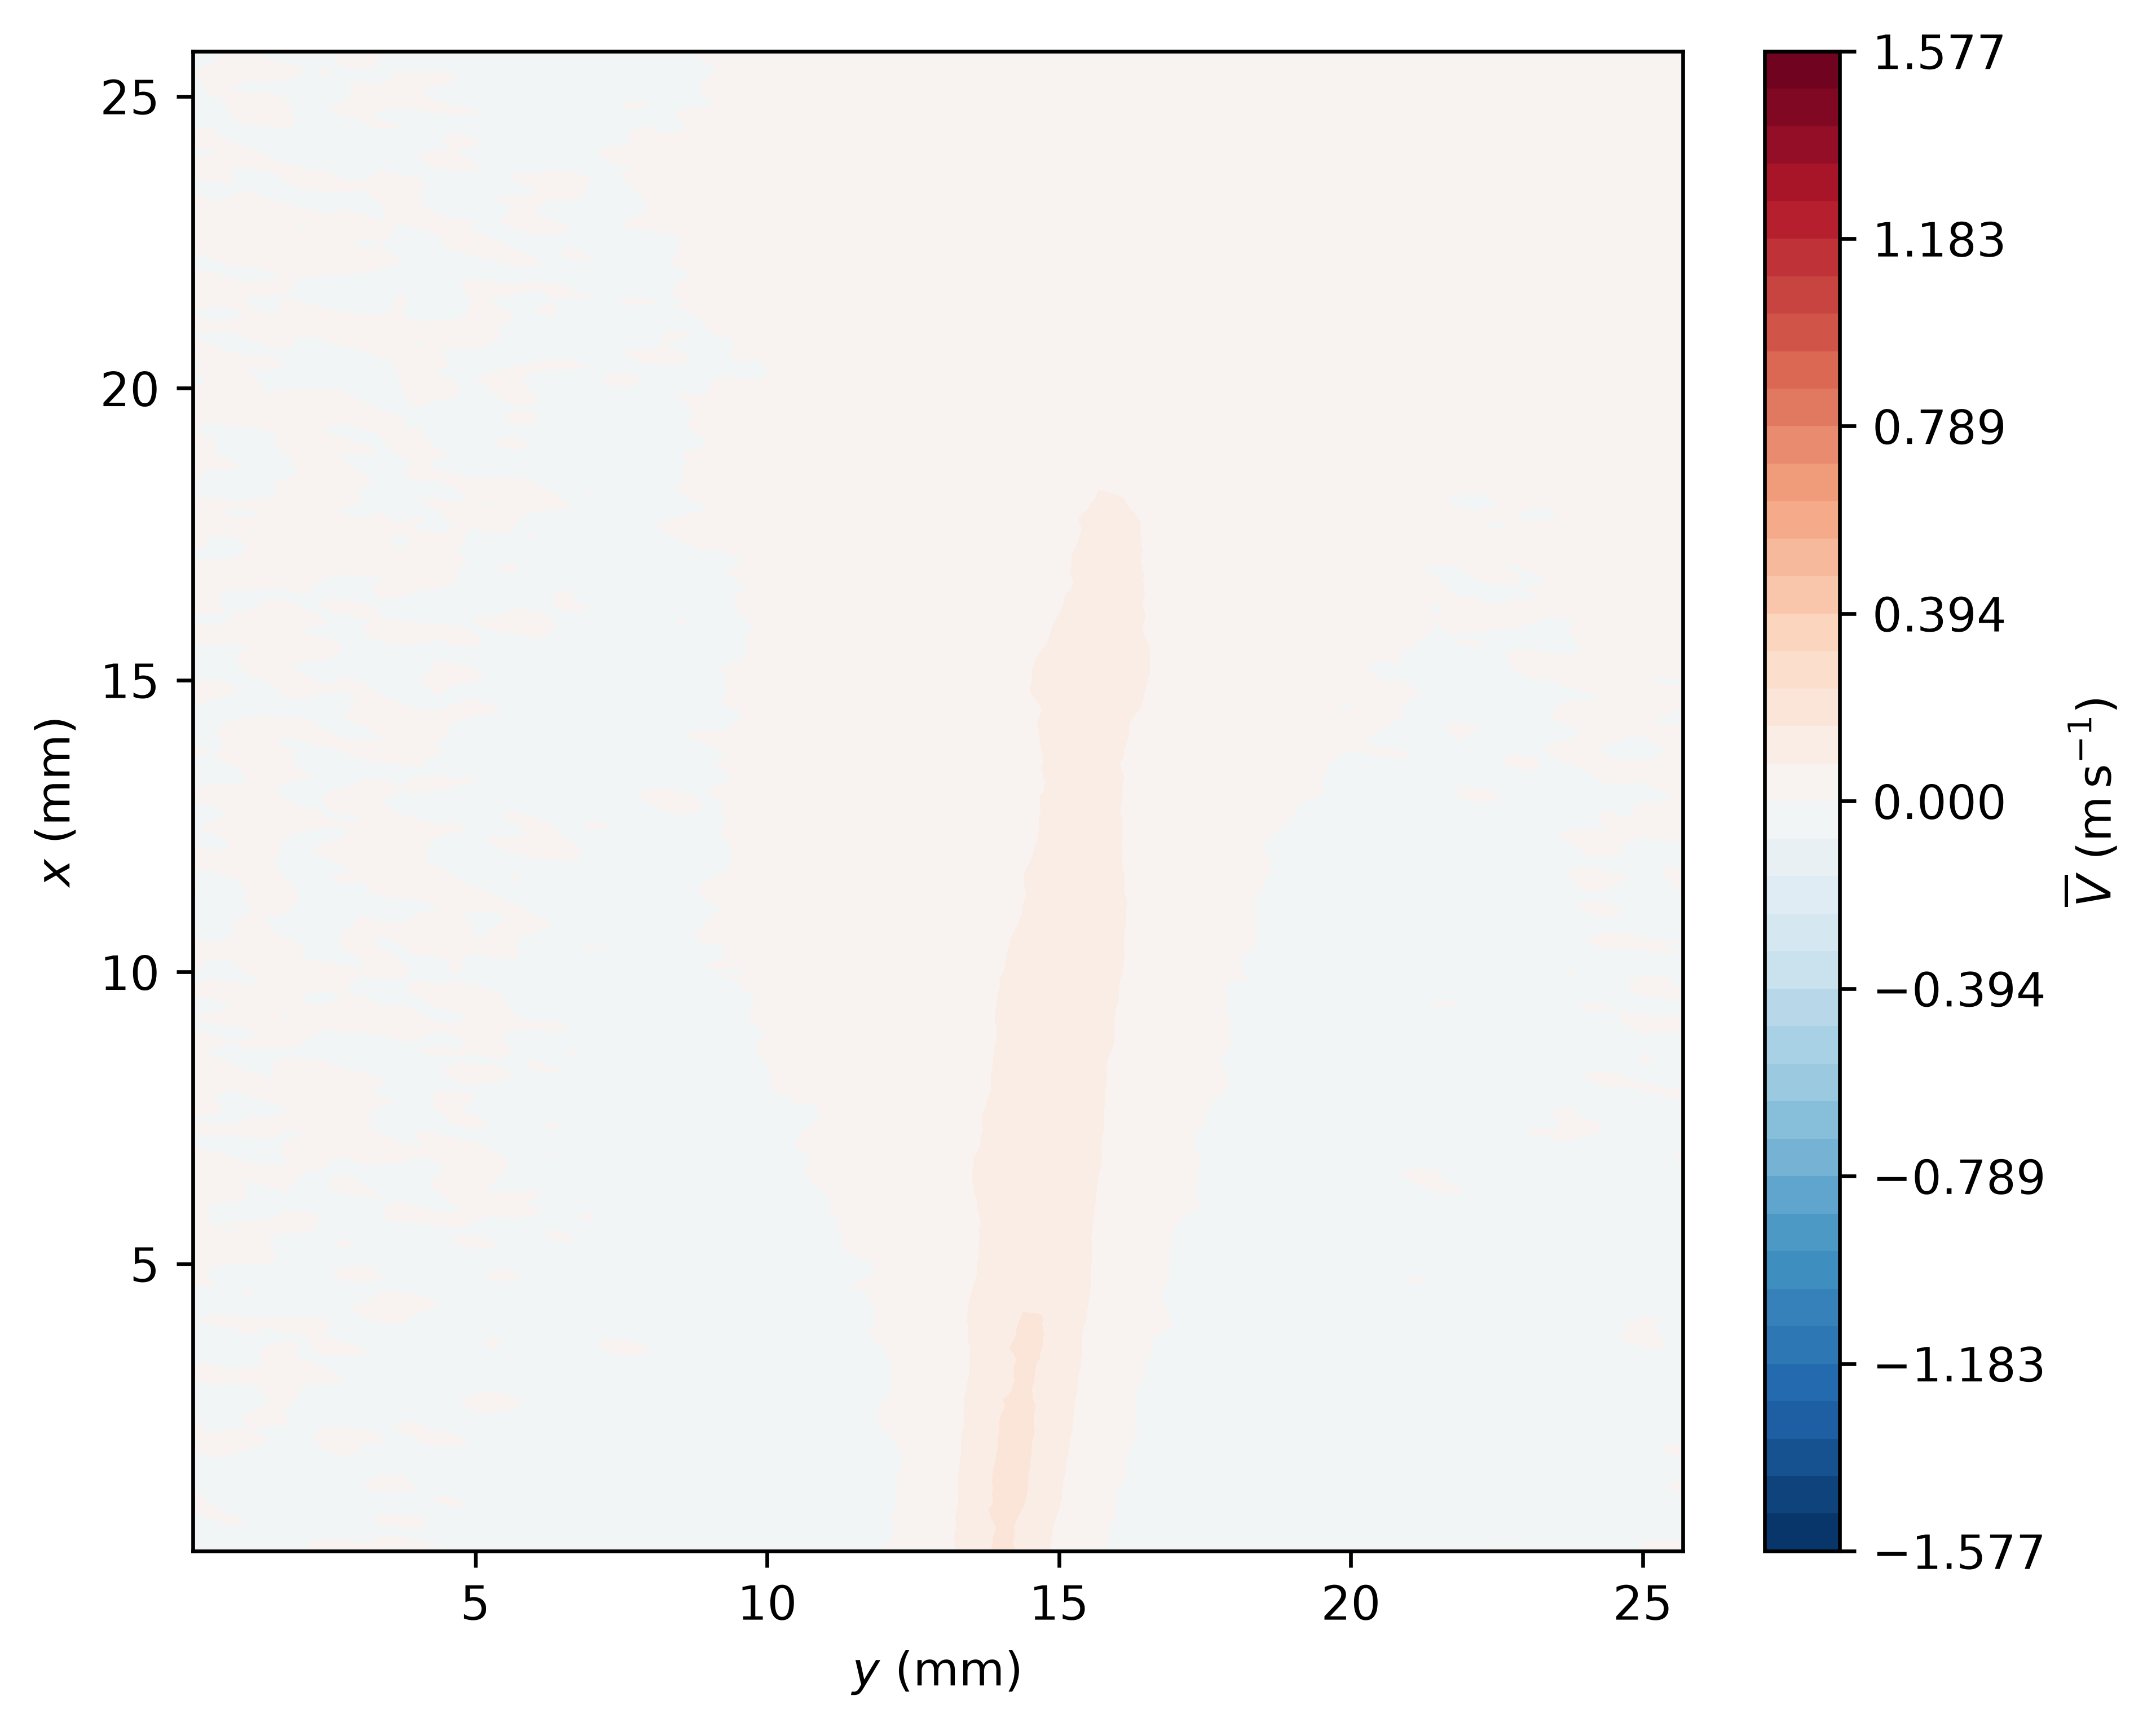

## Supporting component statistics

rms_U


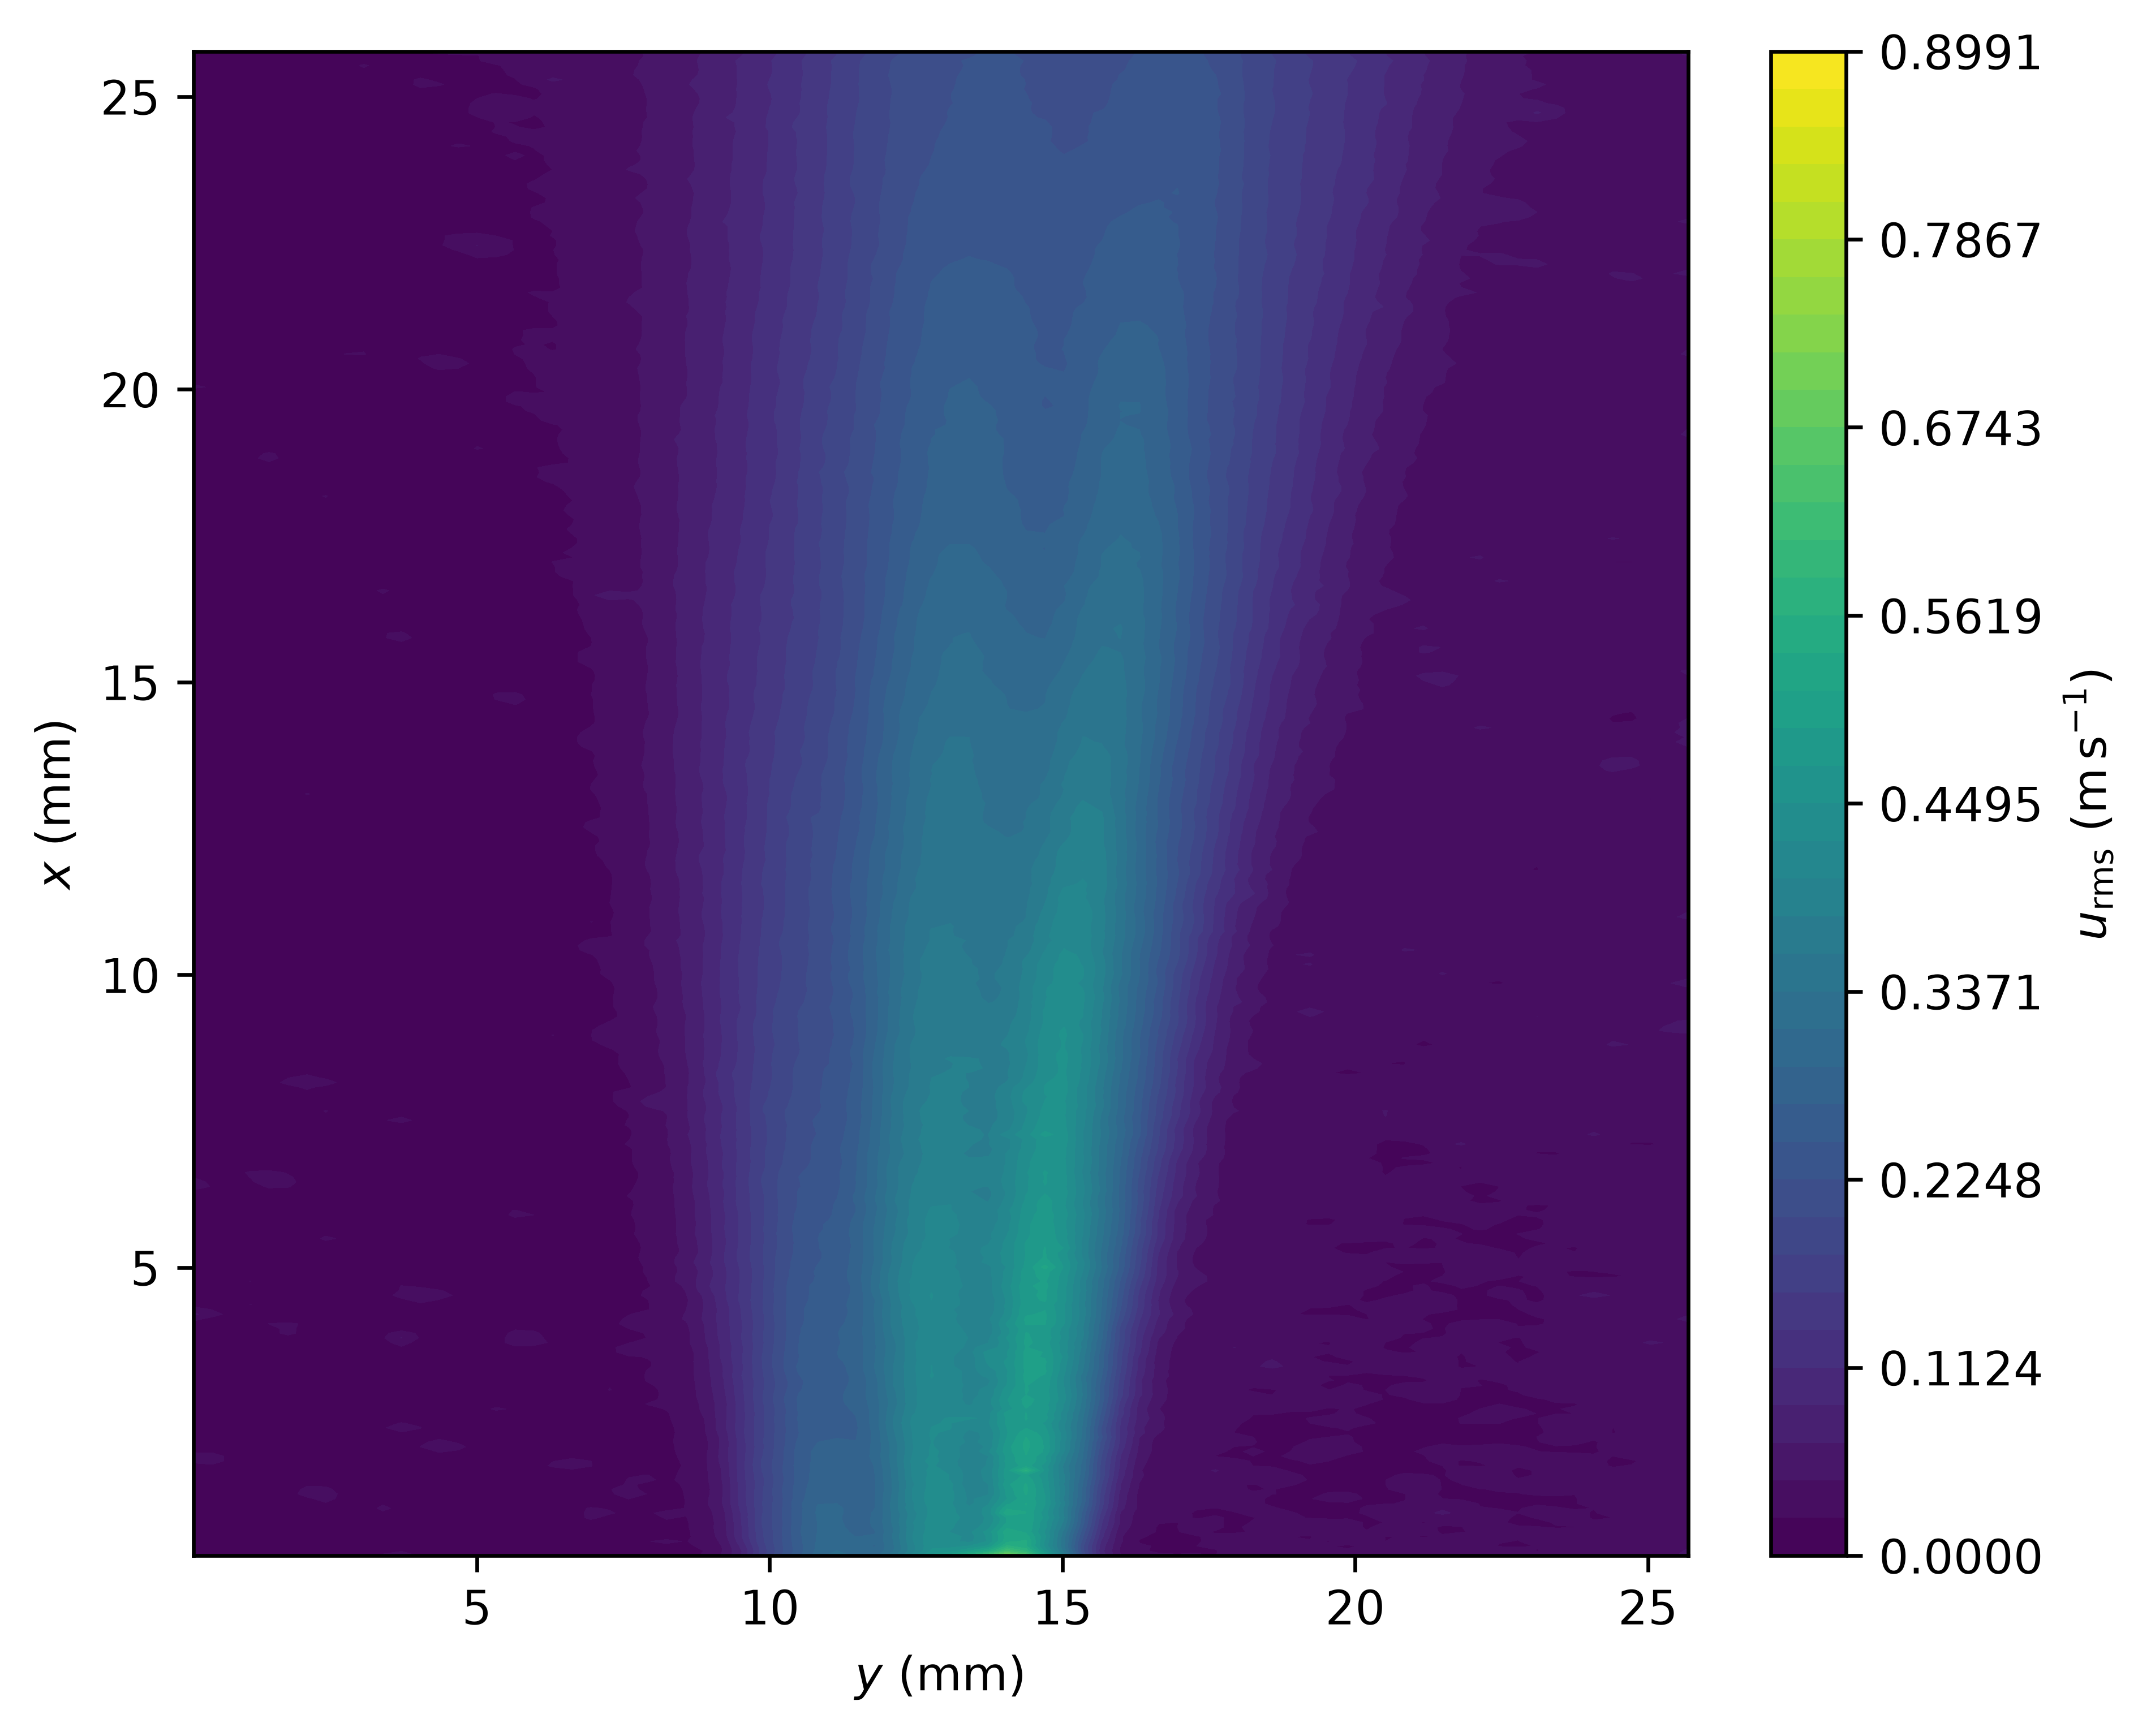

rms_V


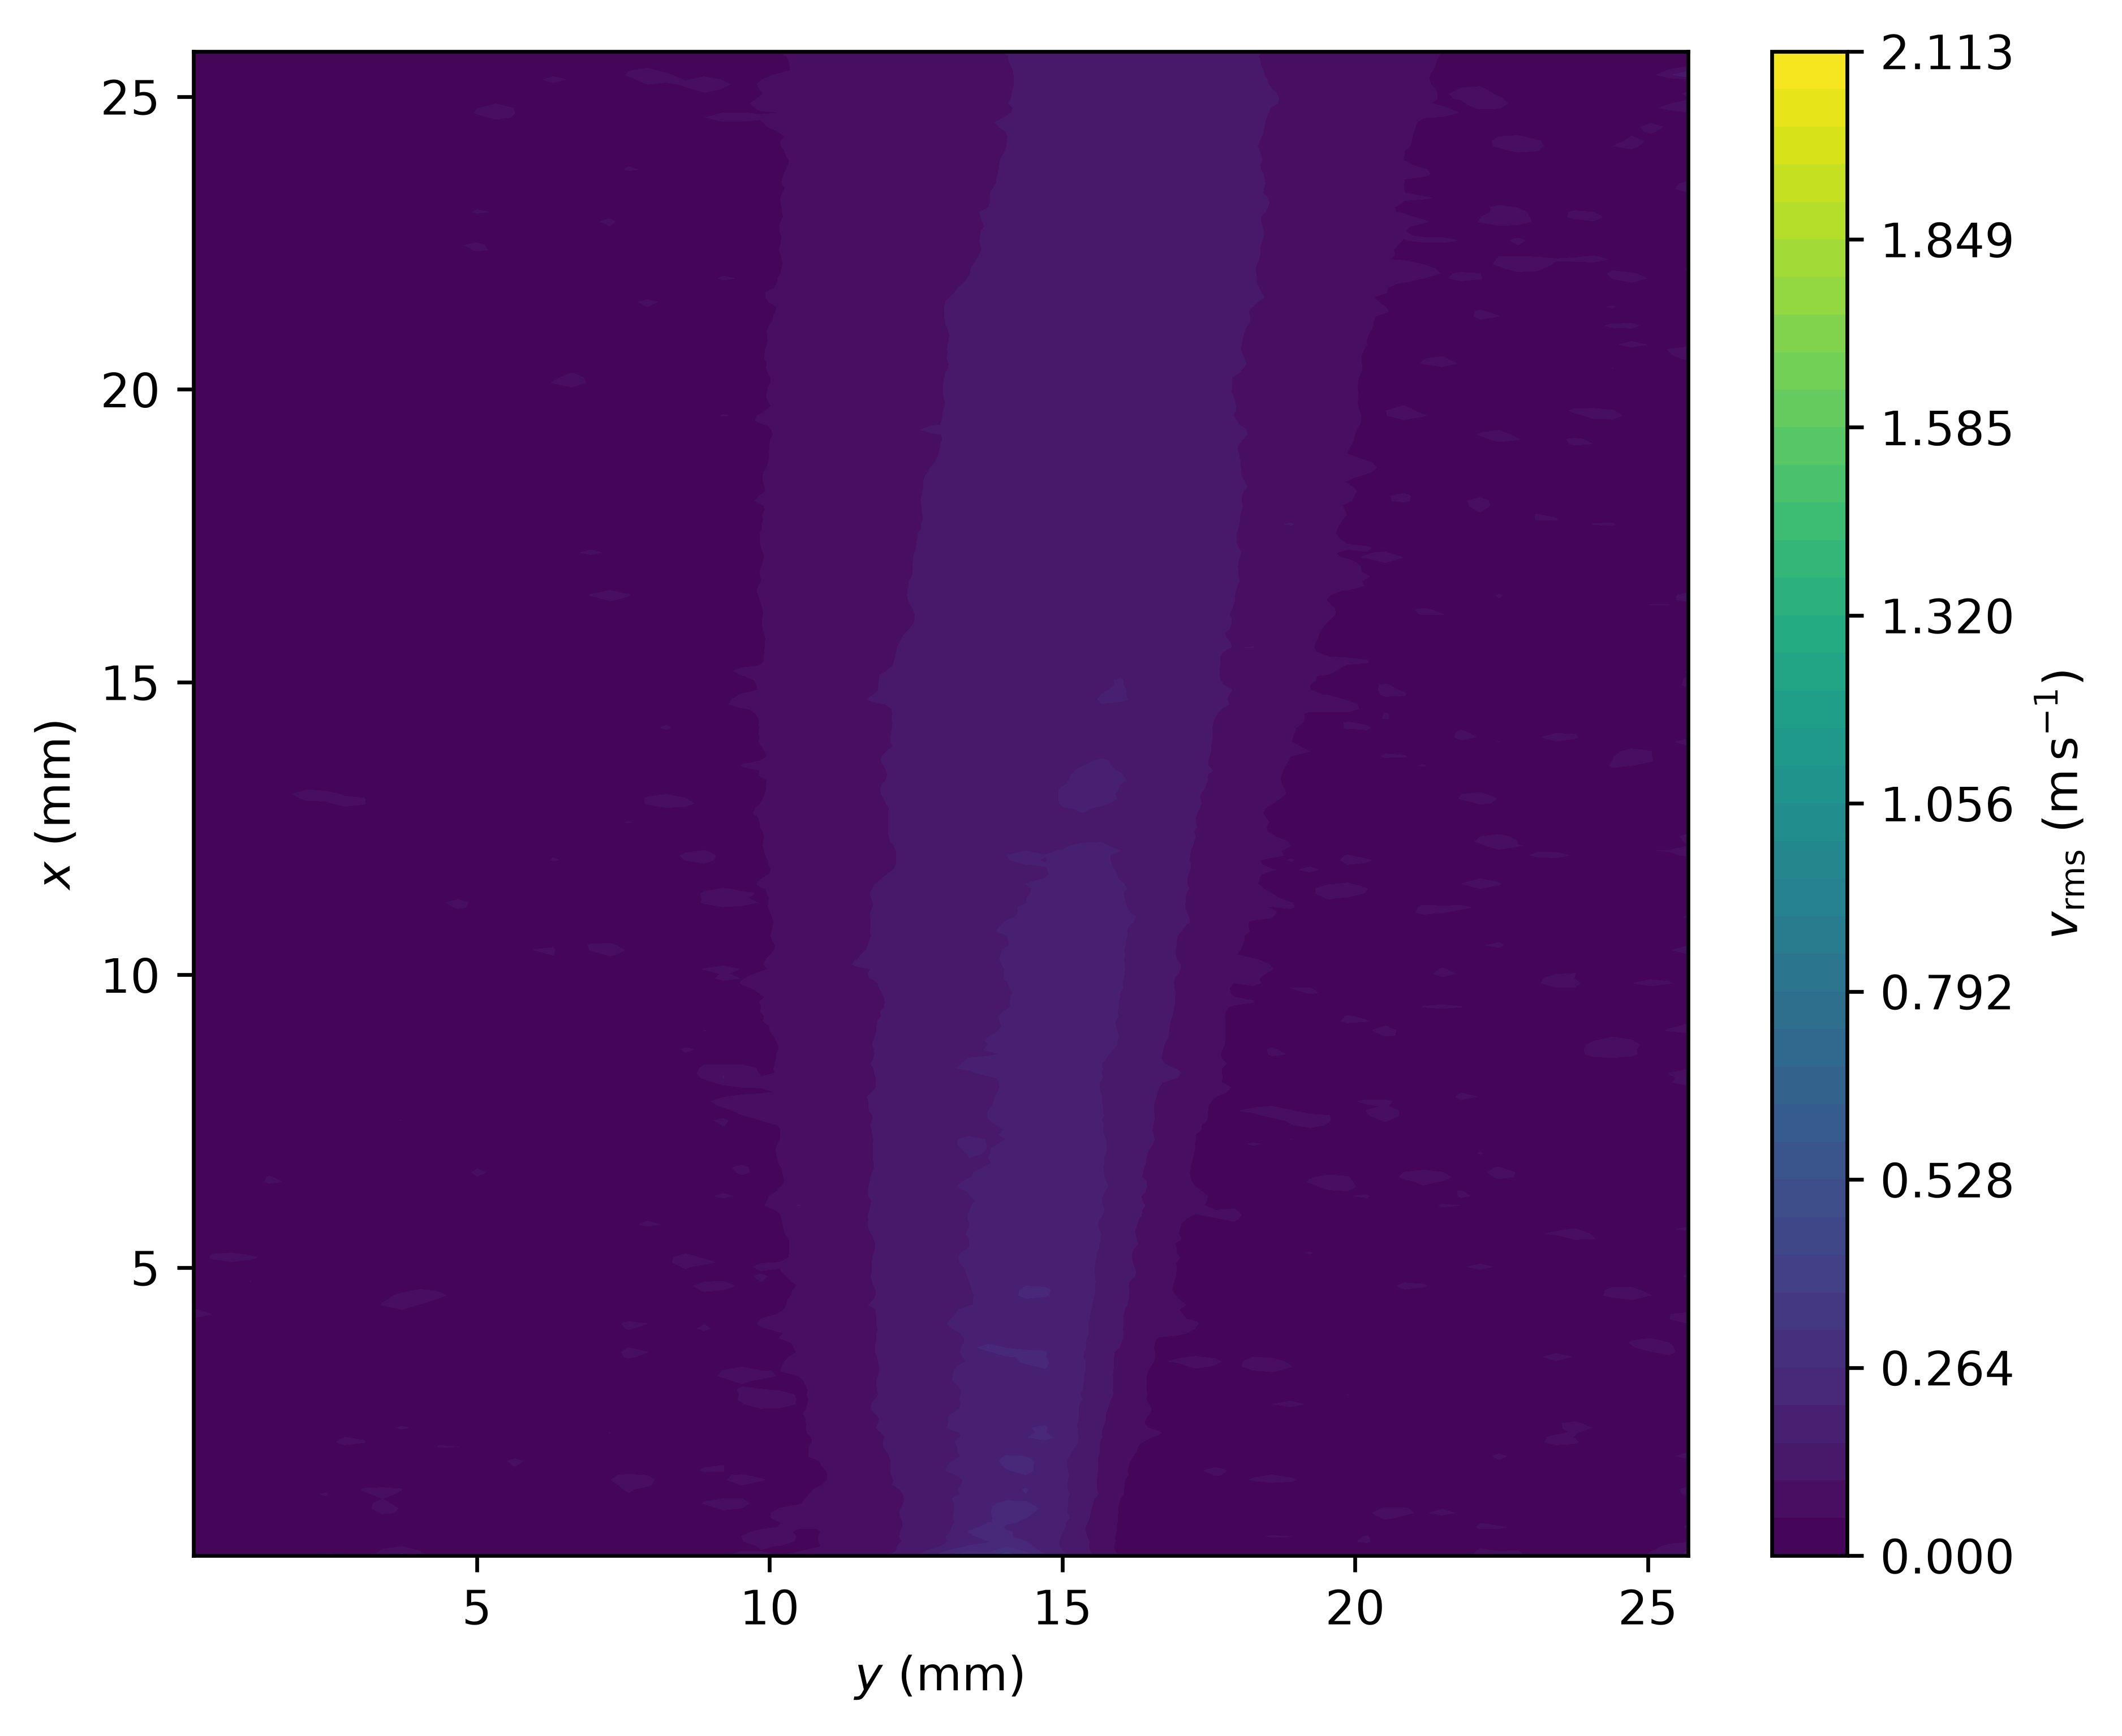

covariance


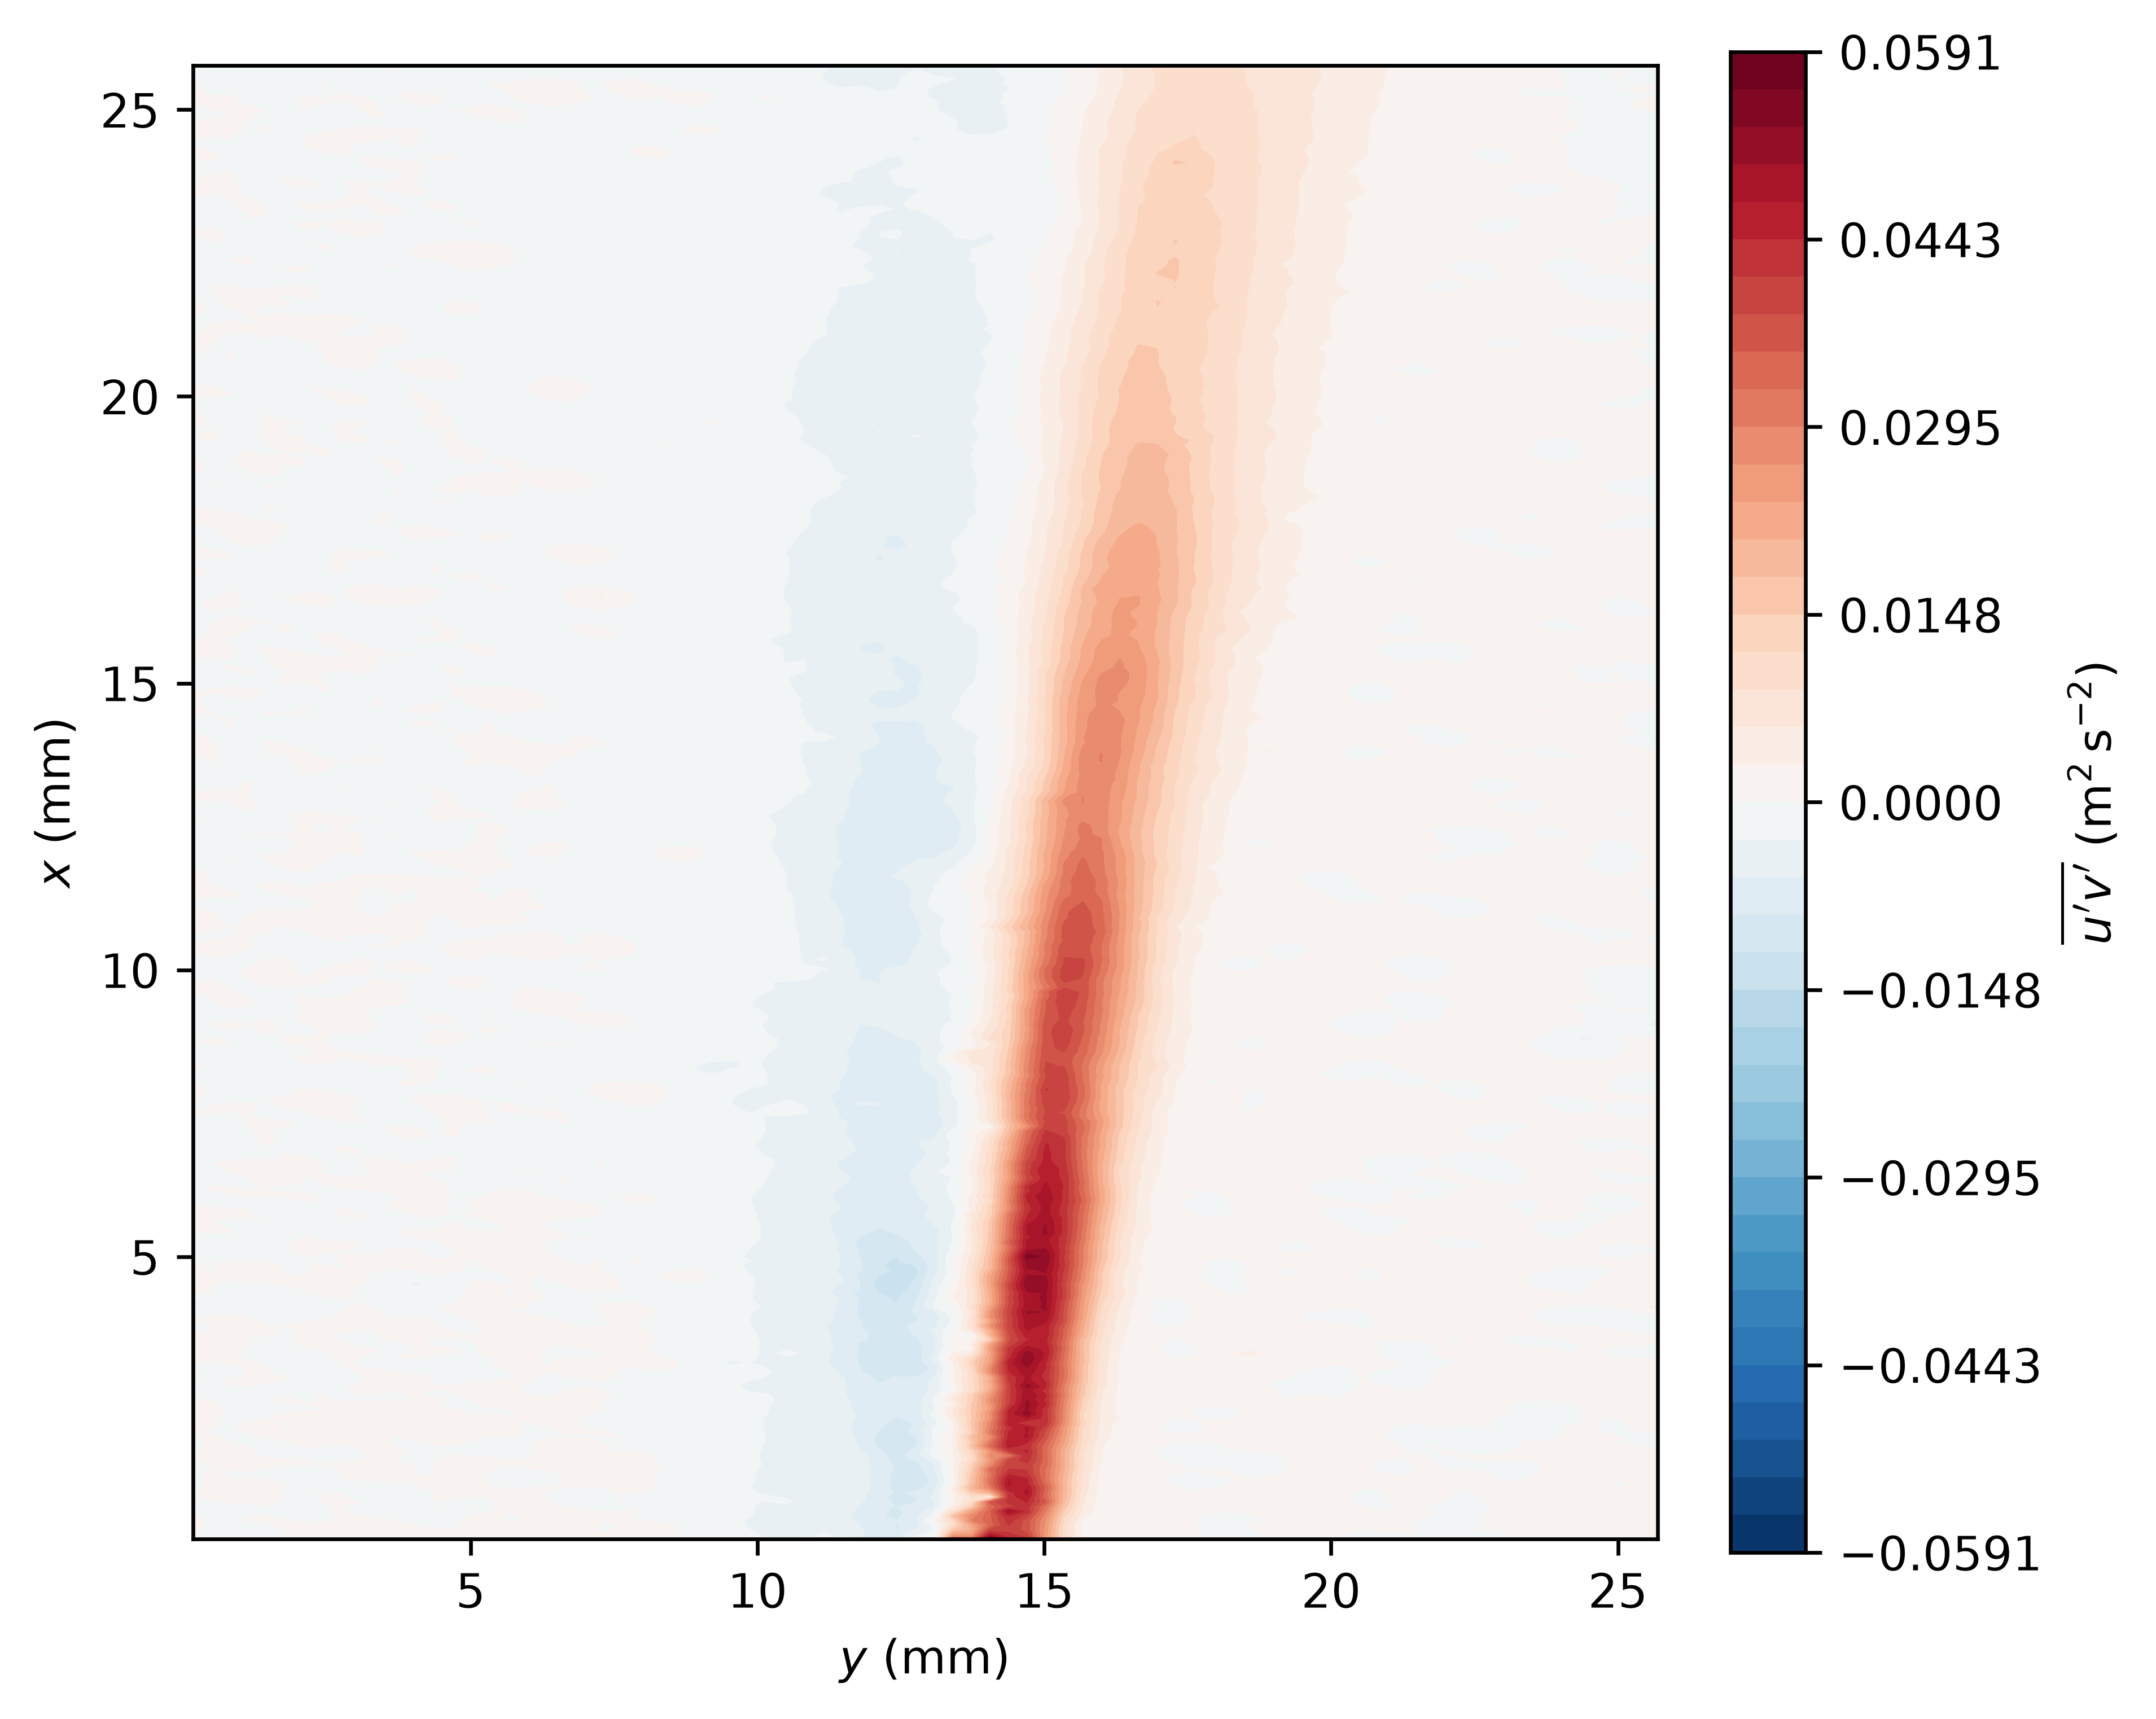

correlation


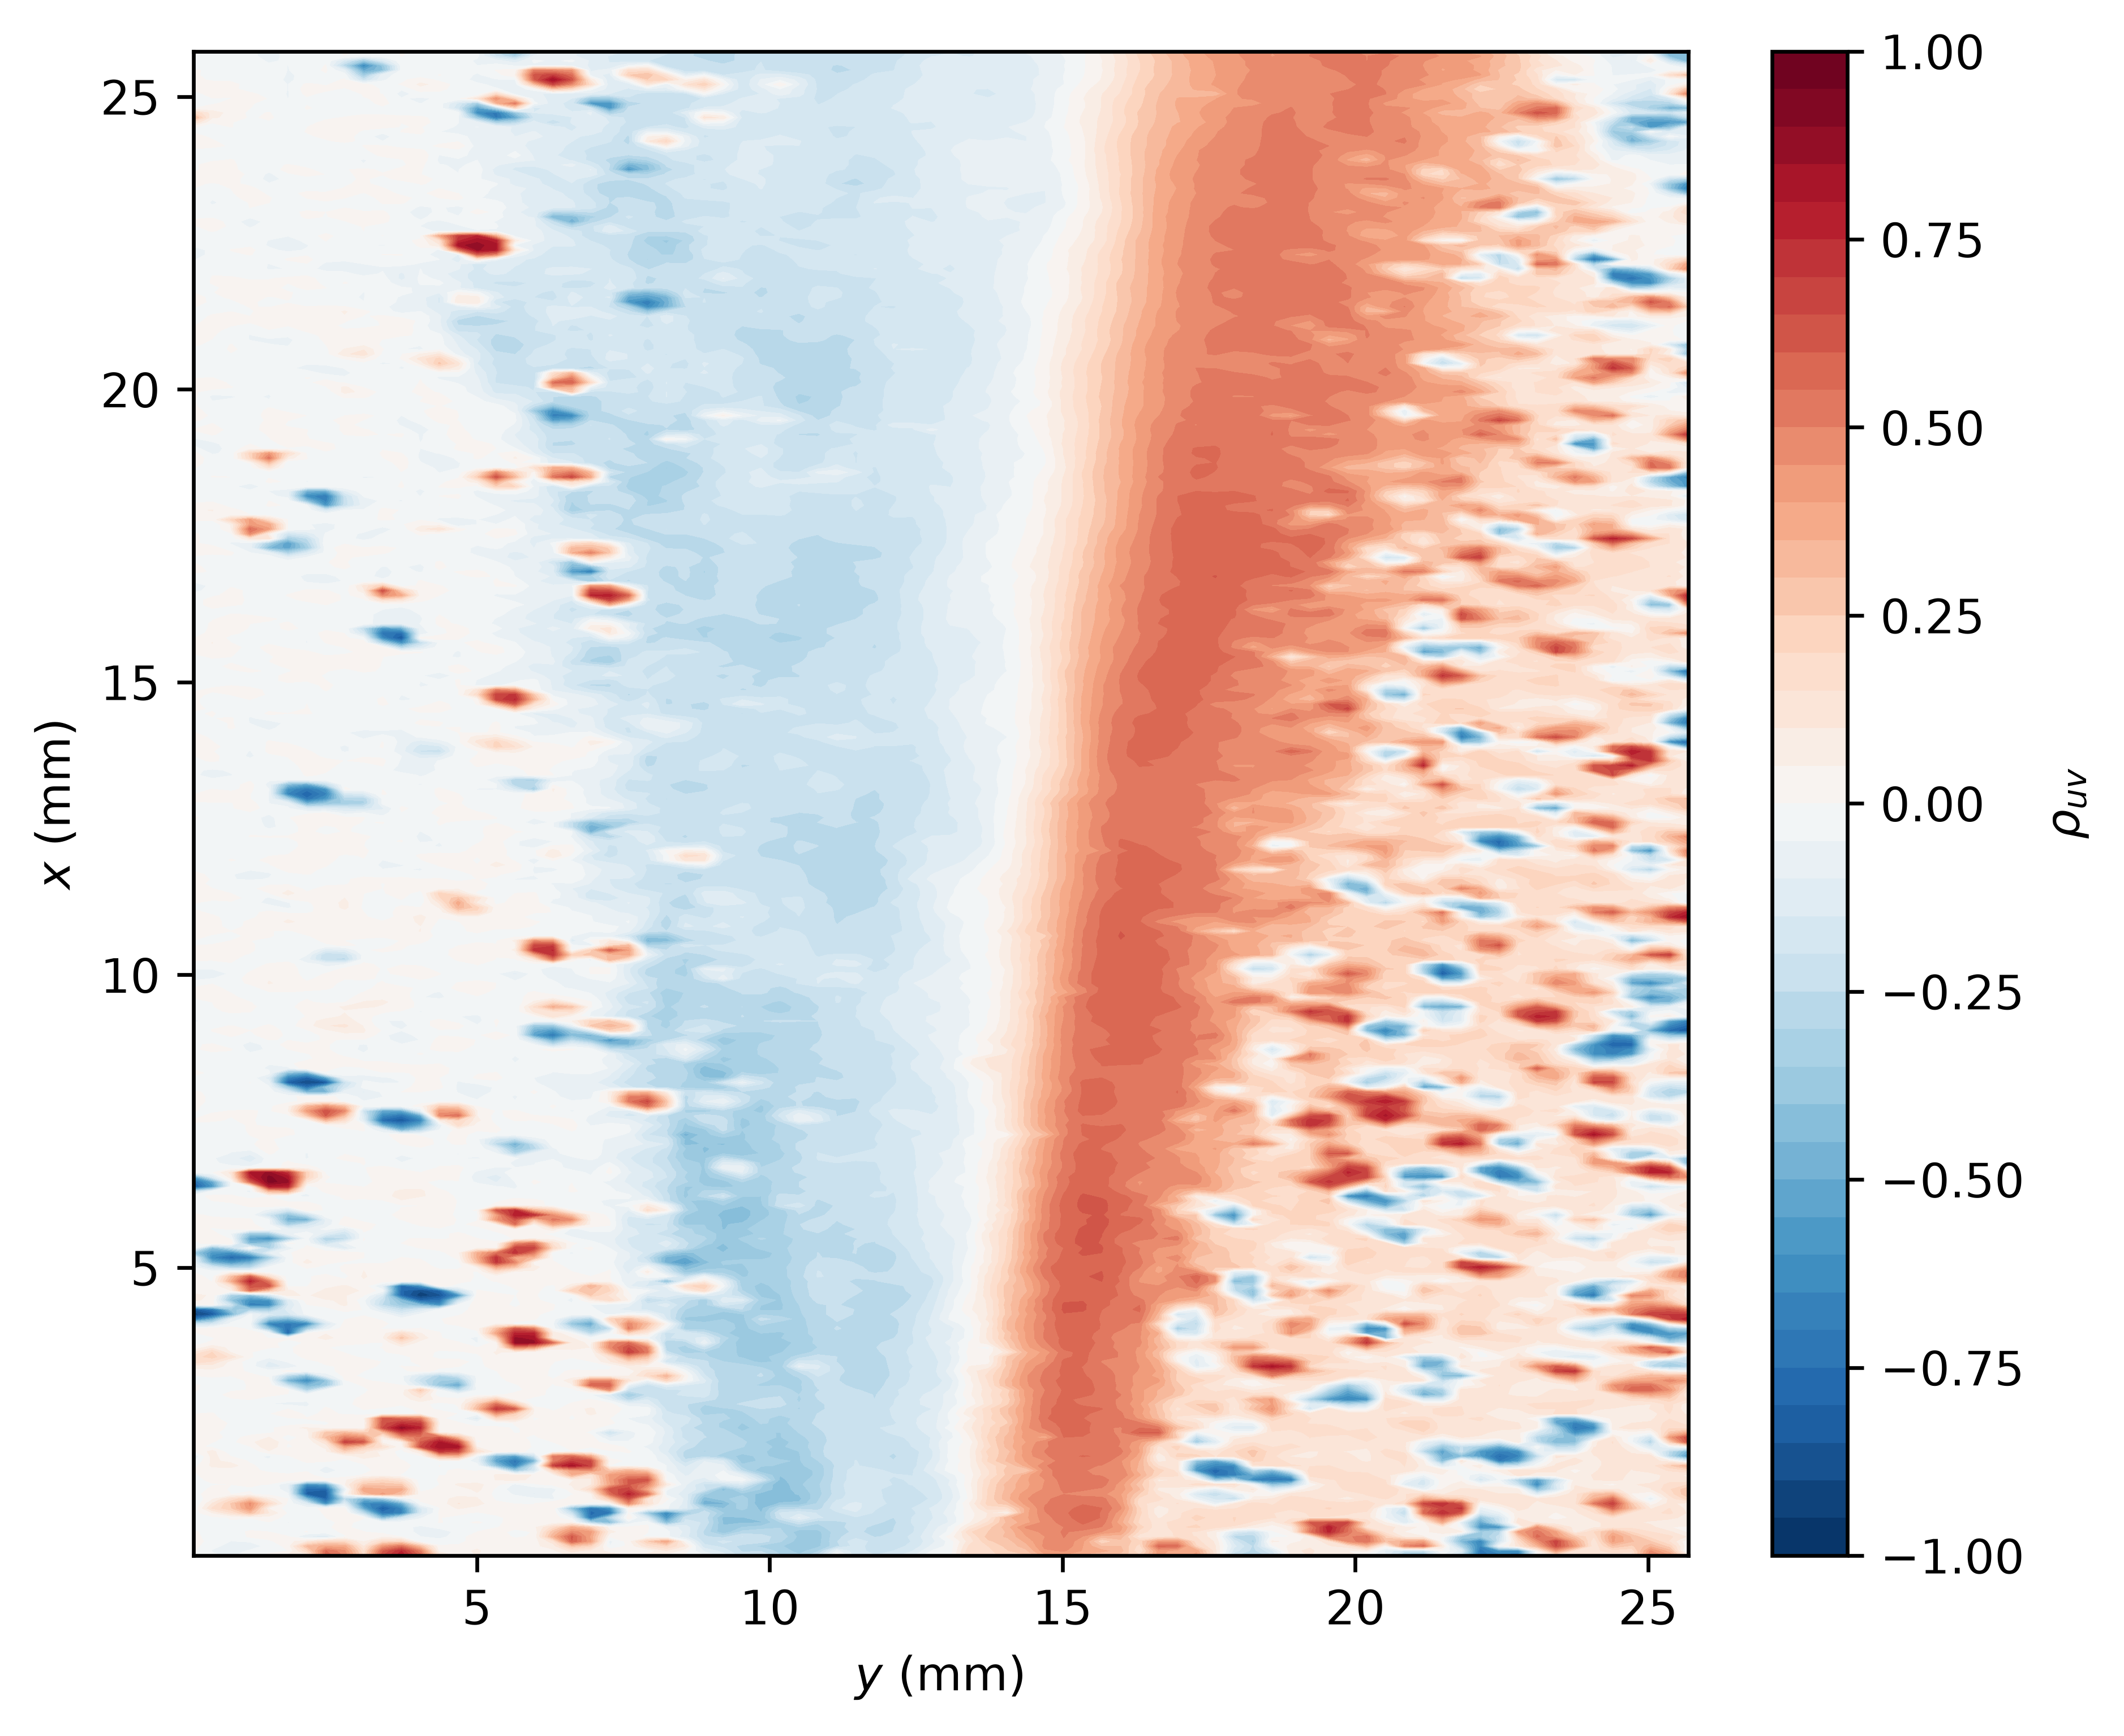

sampling_stations


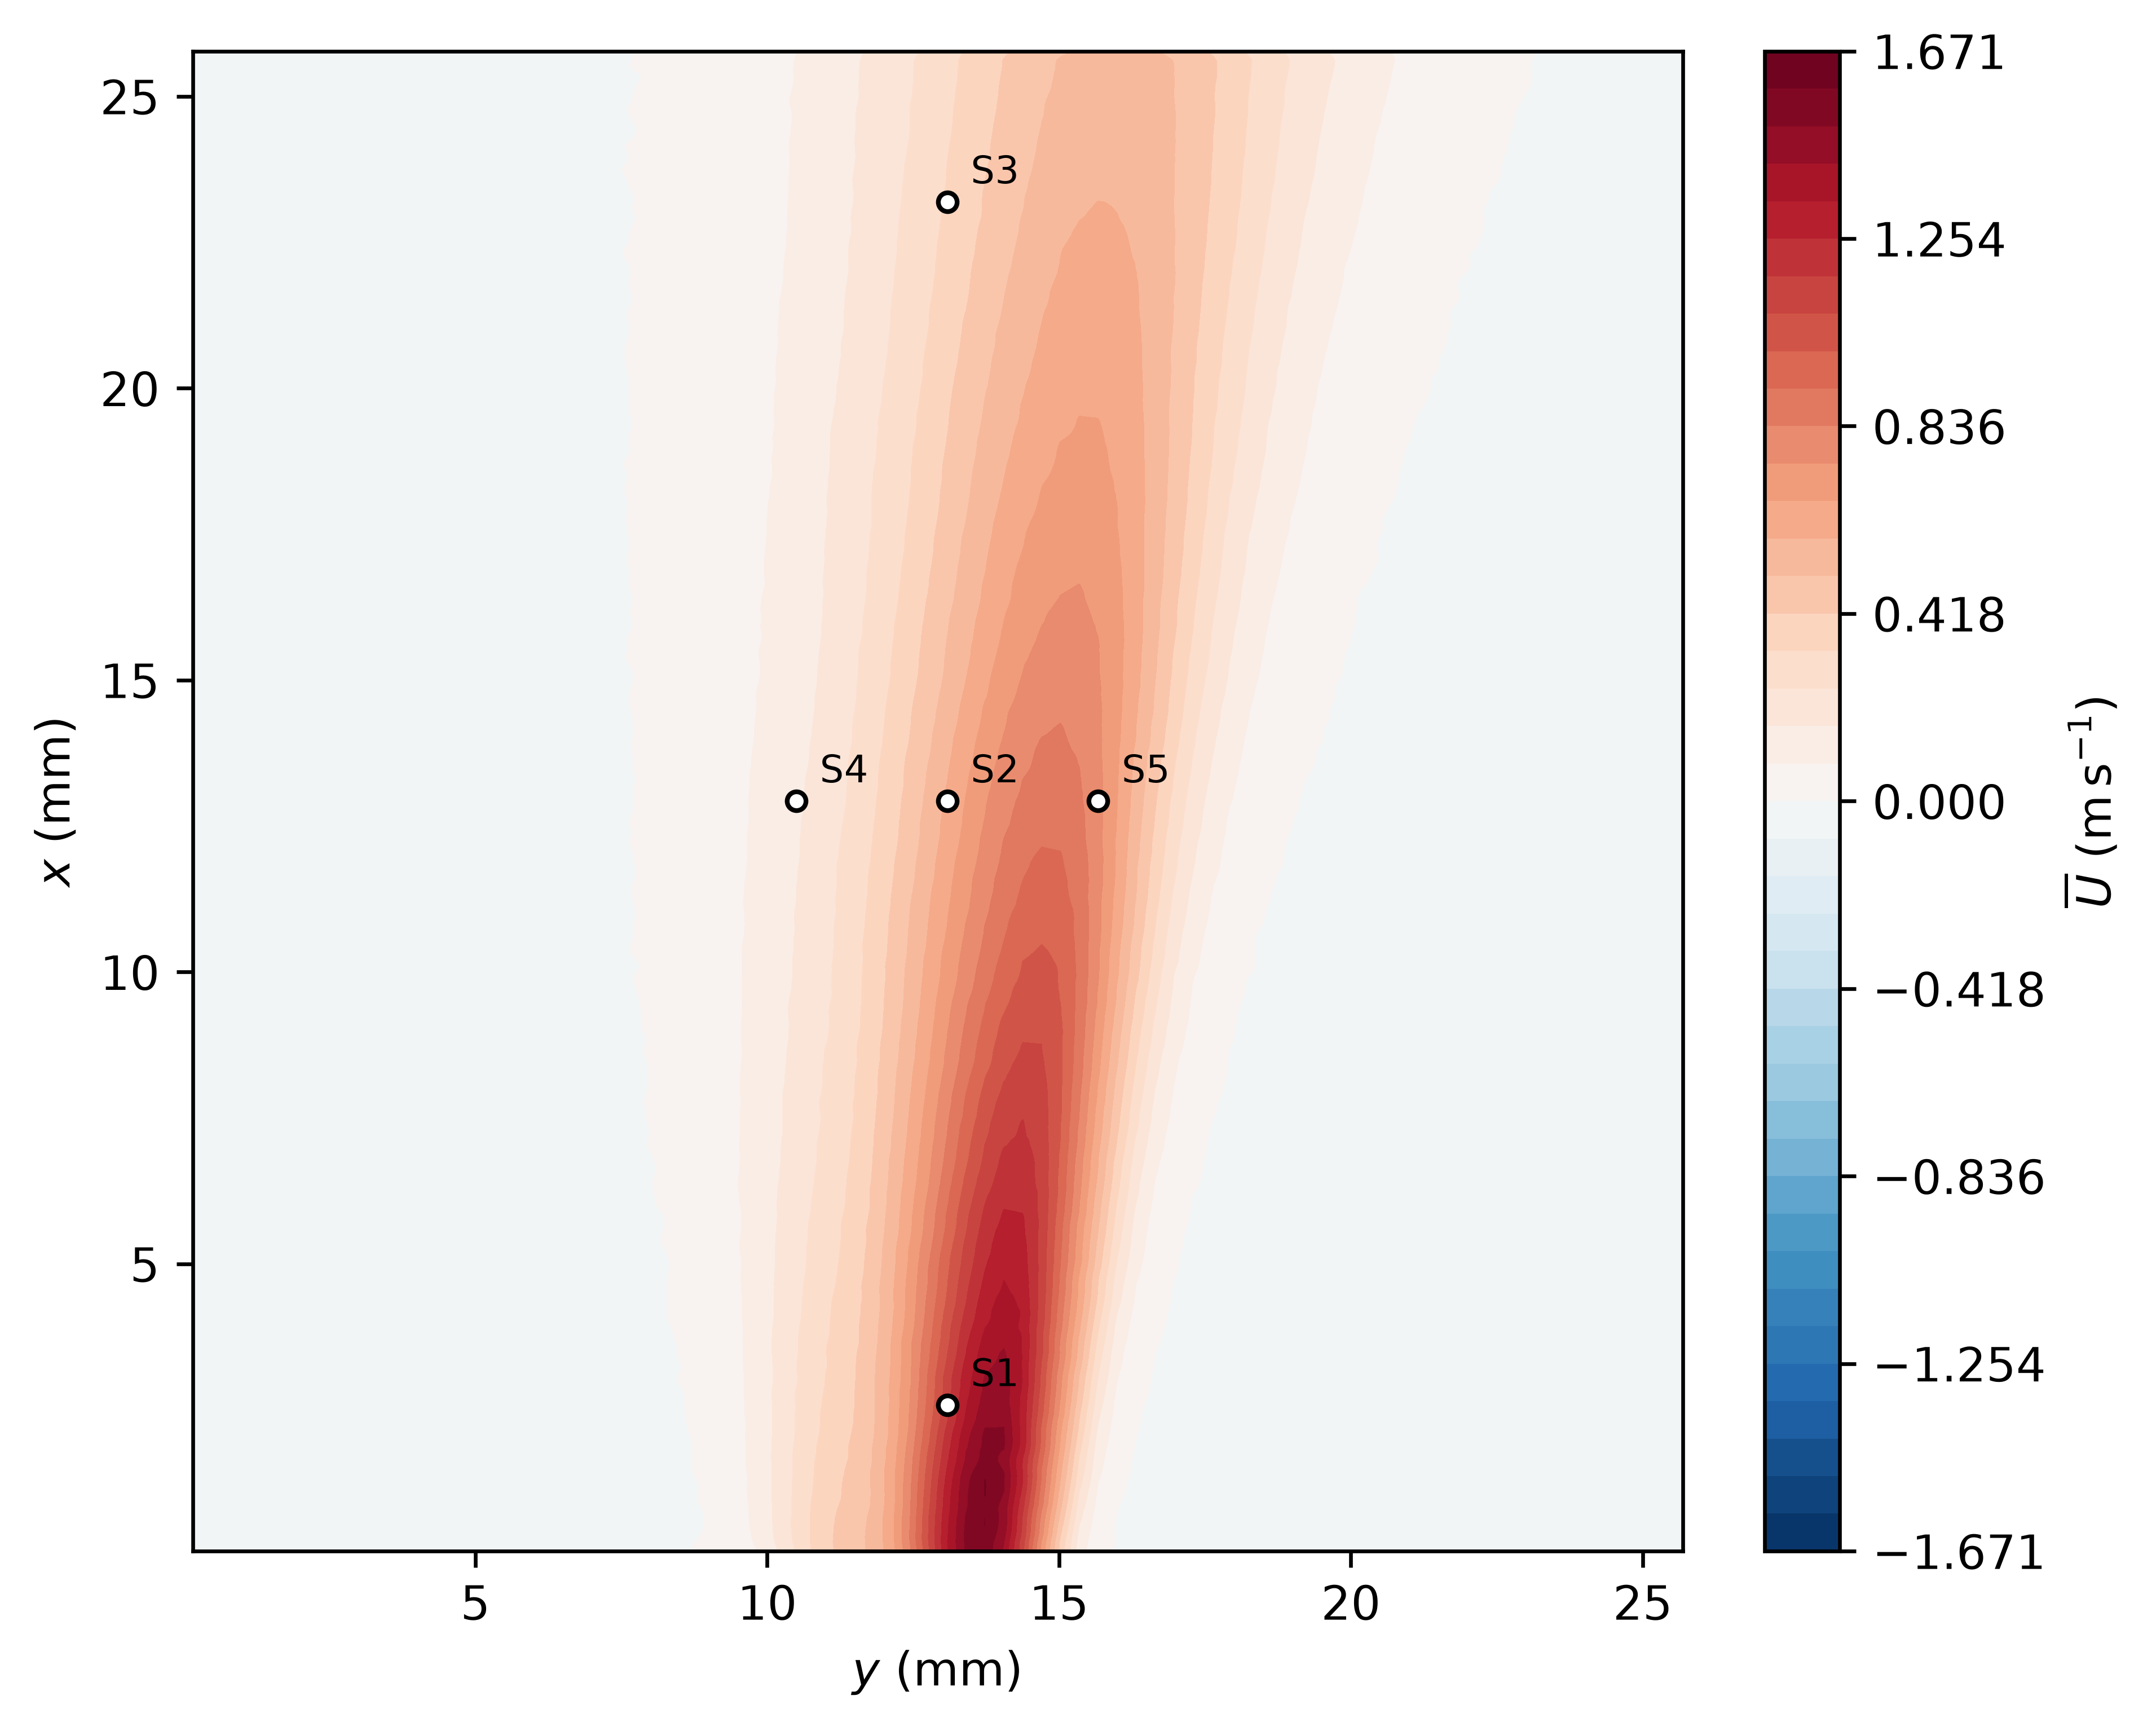

profile_mean_U


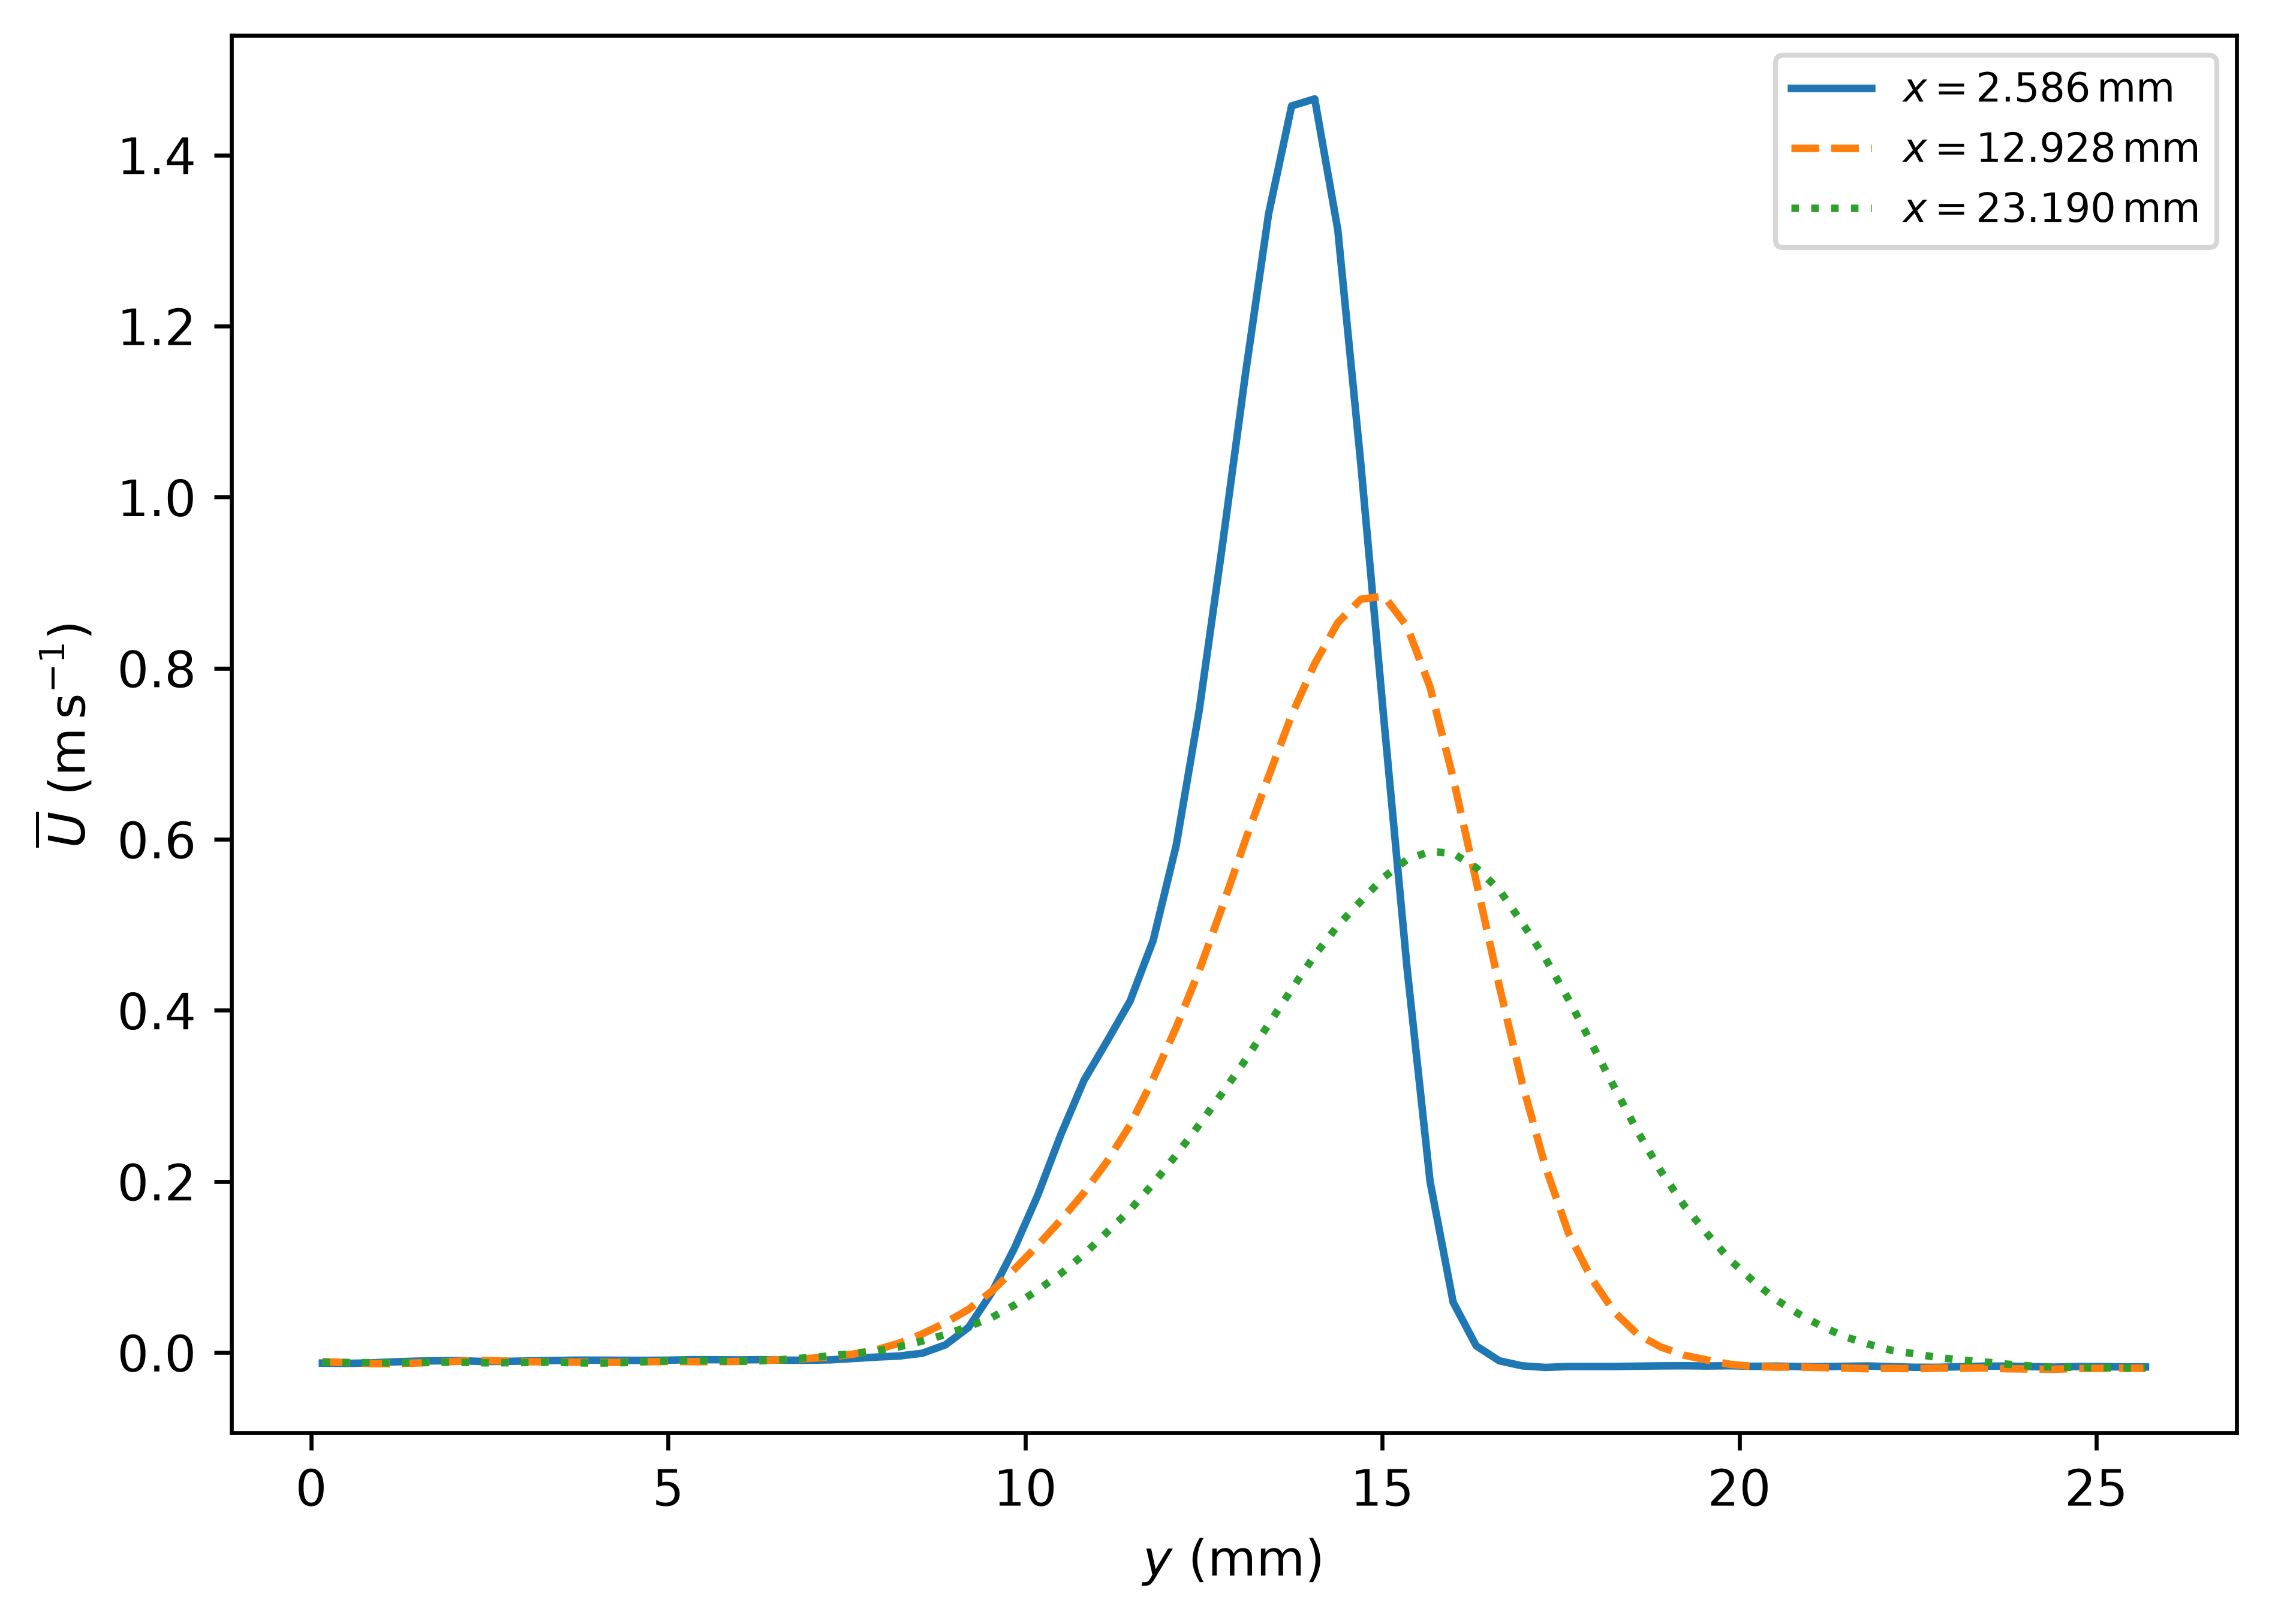

profile_mean_V


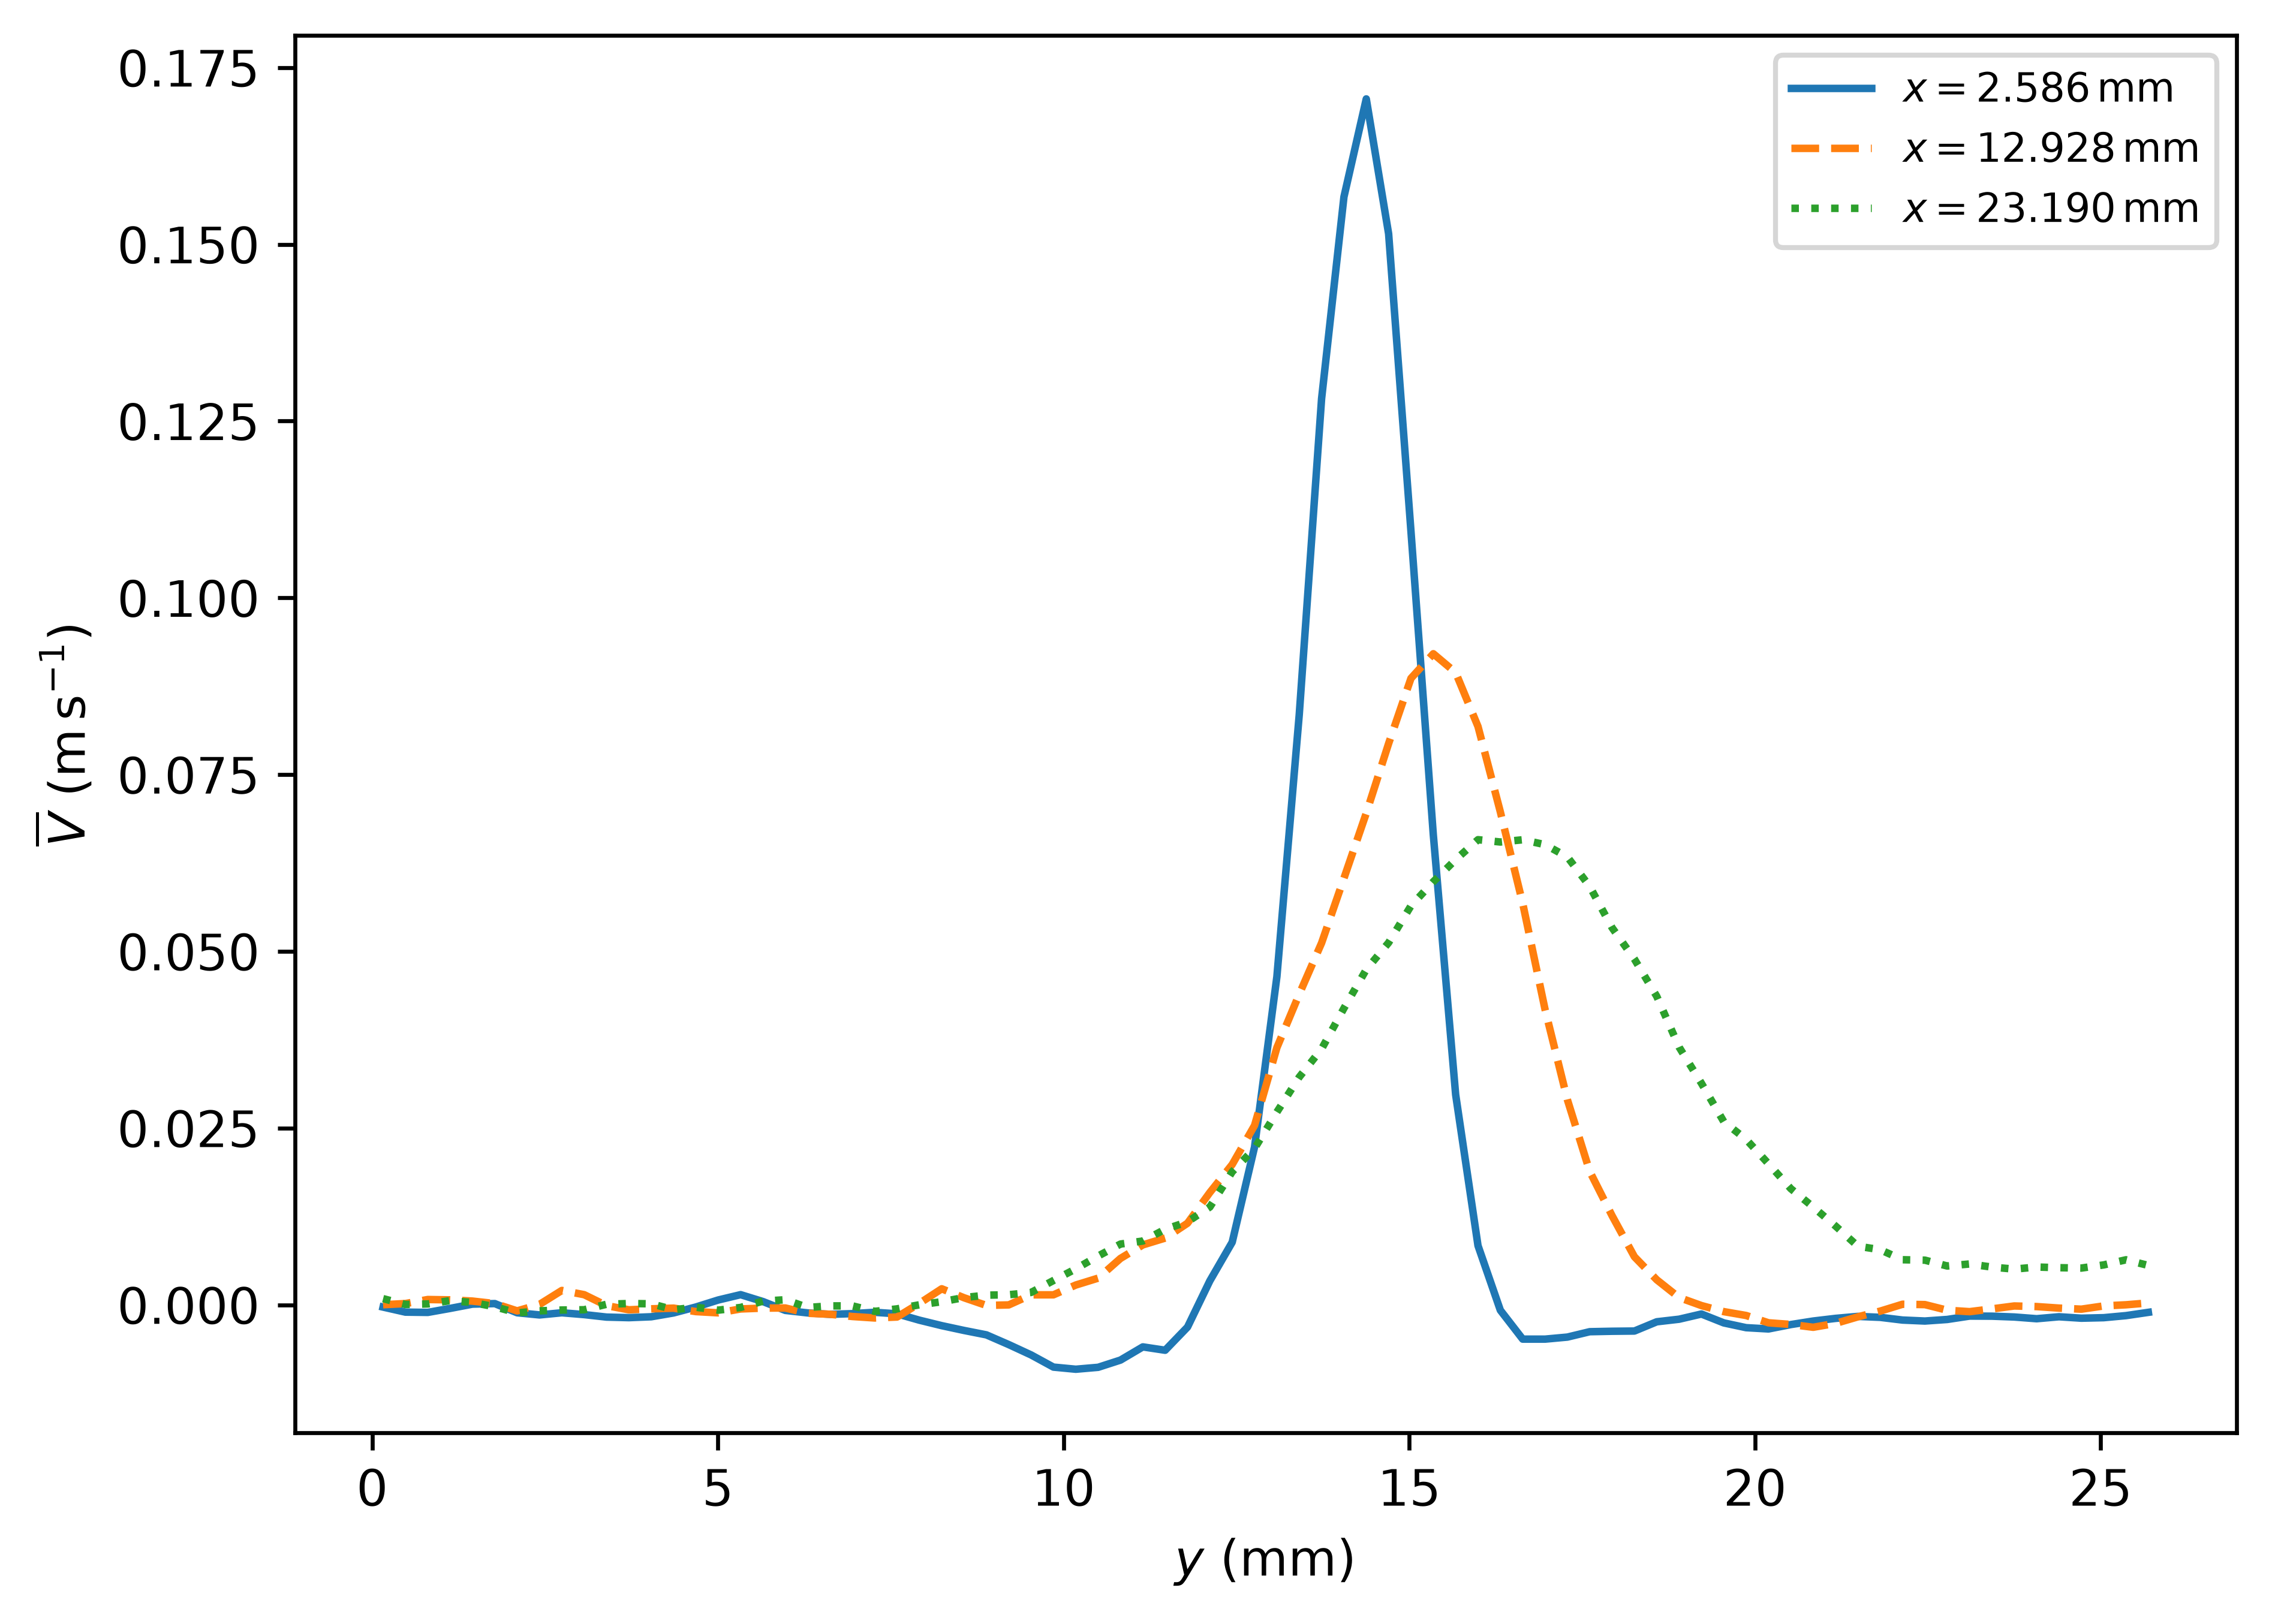

profile_rms_U


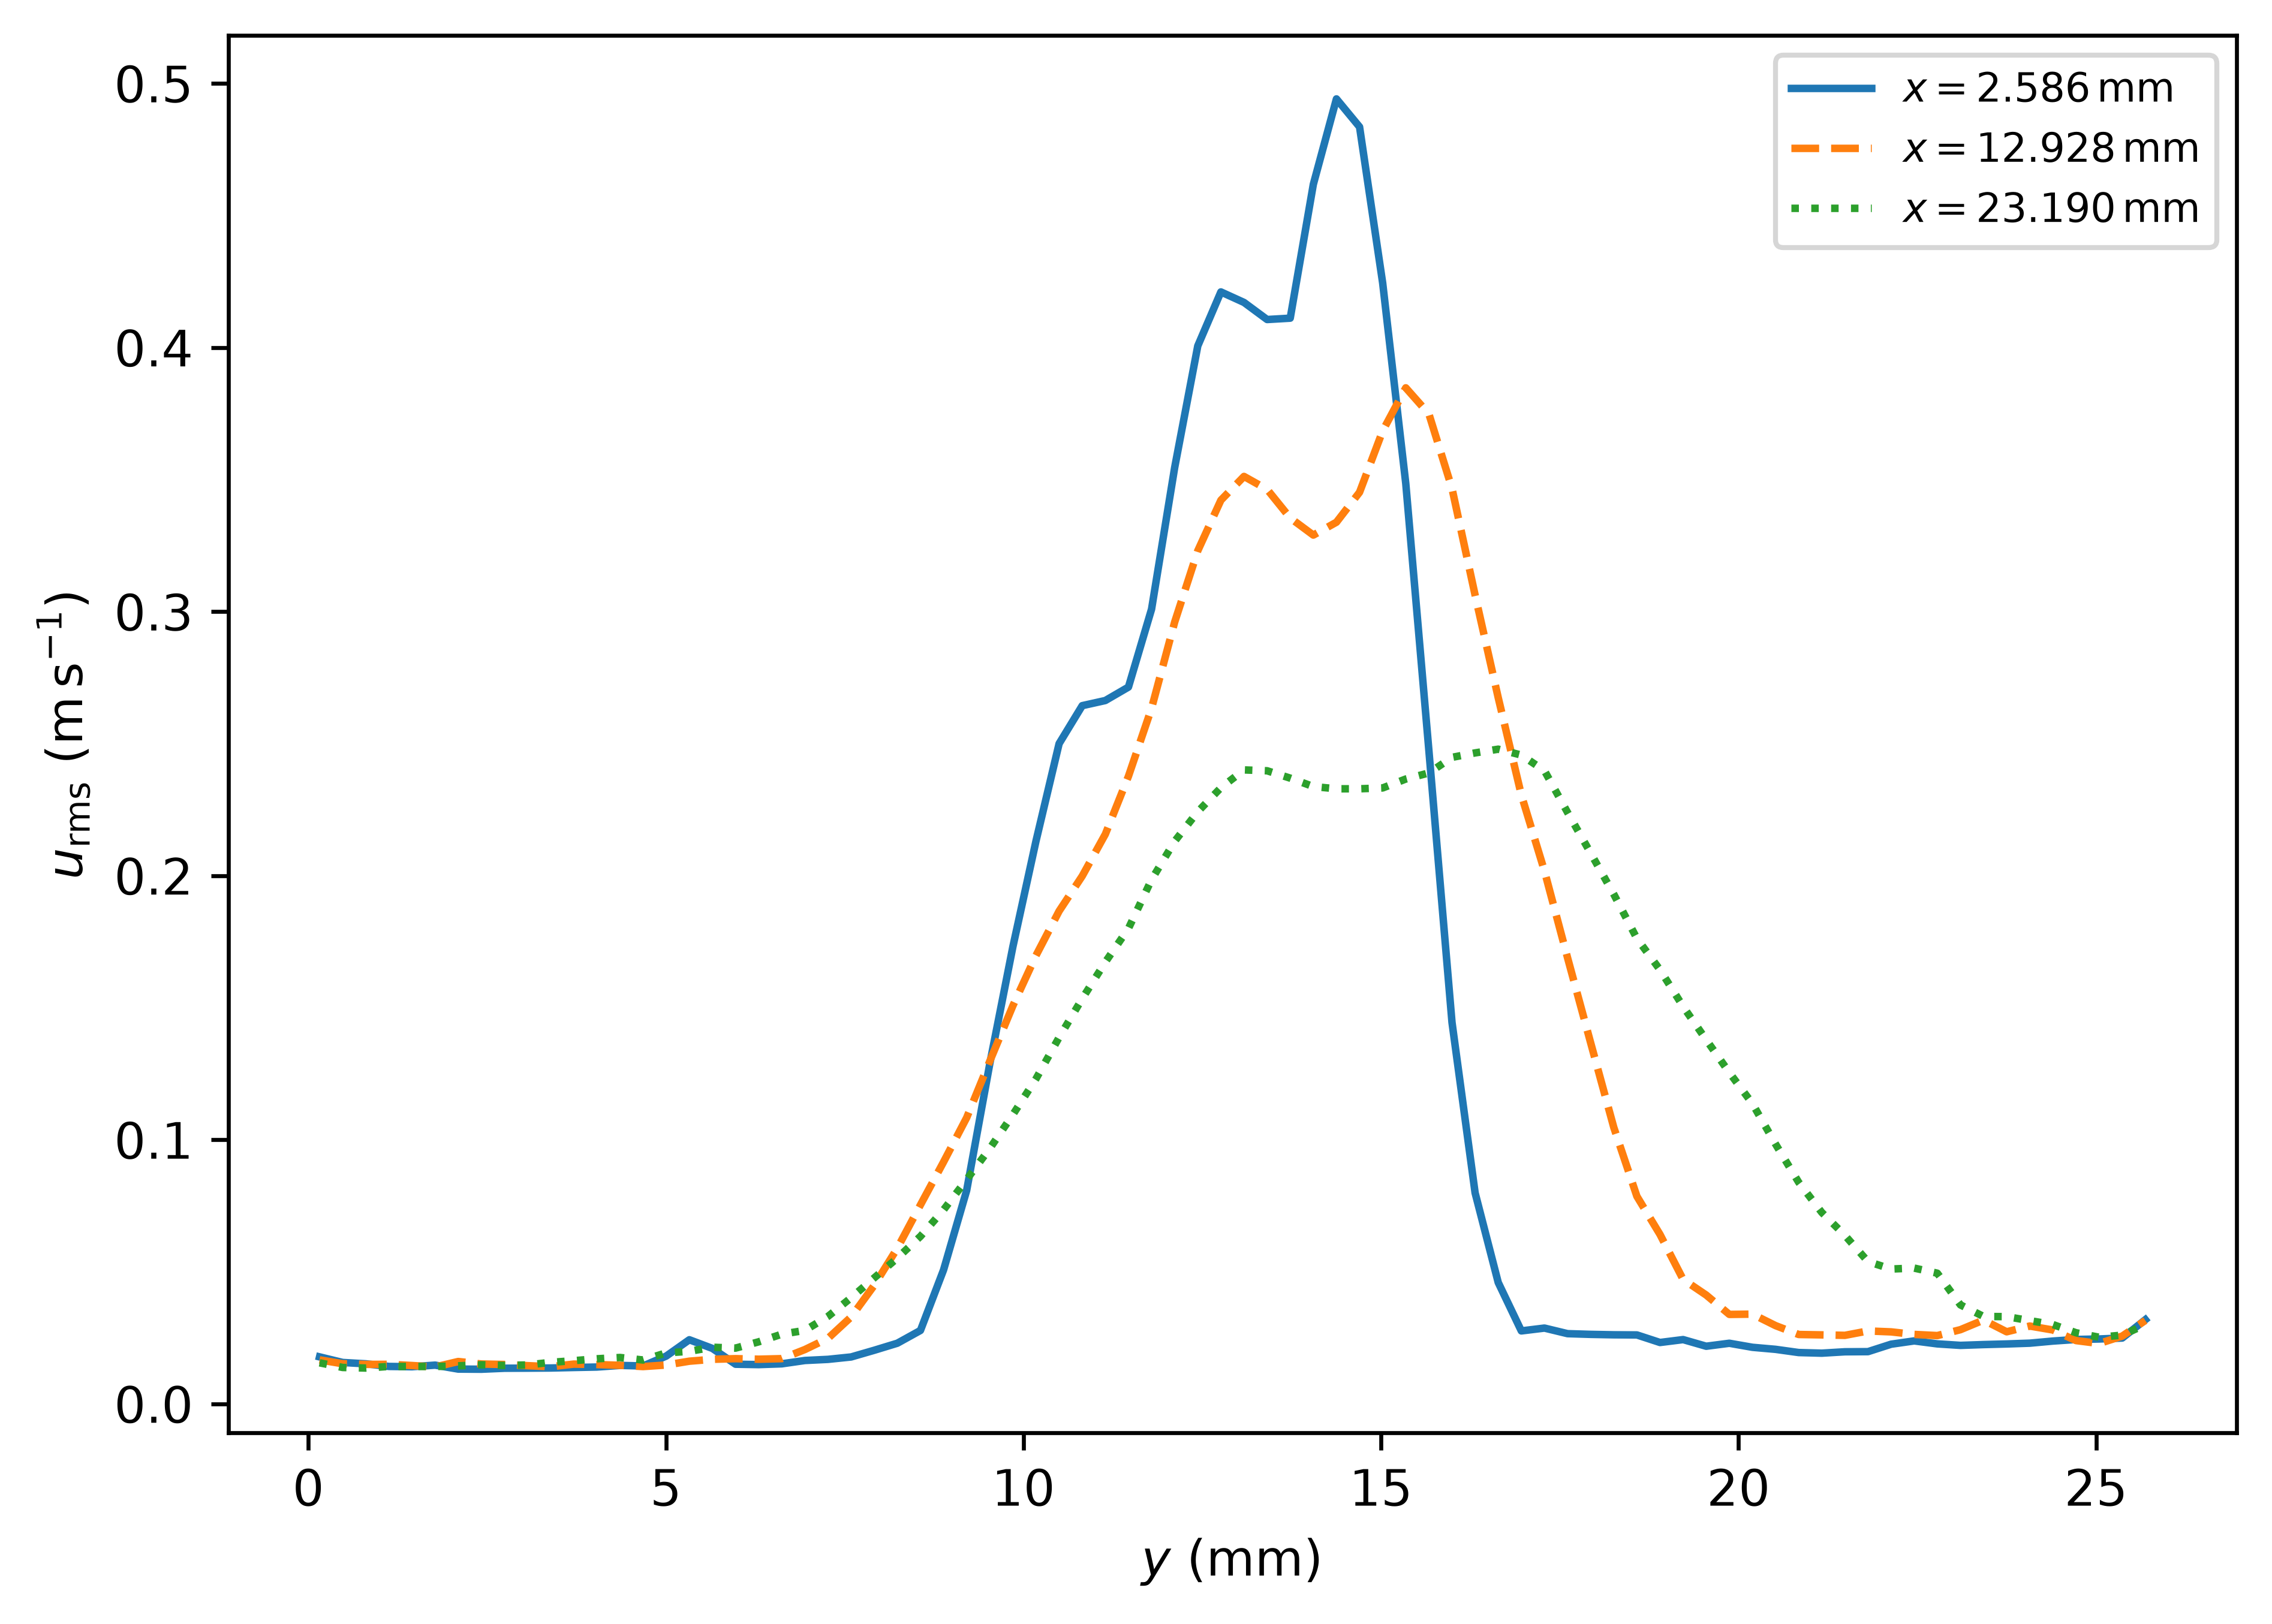

U_pdf


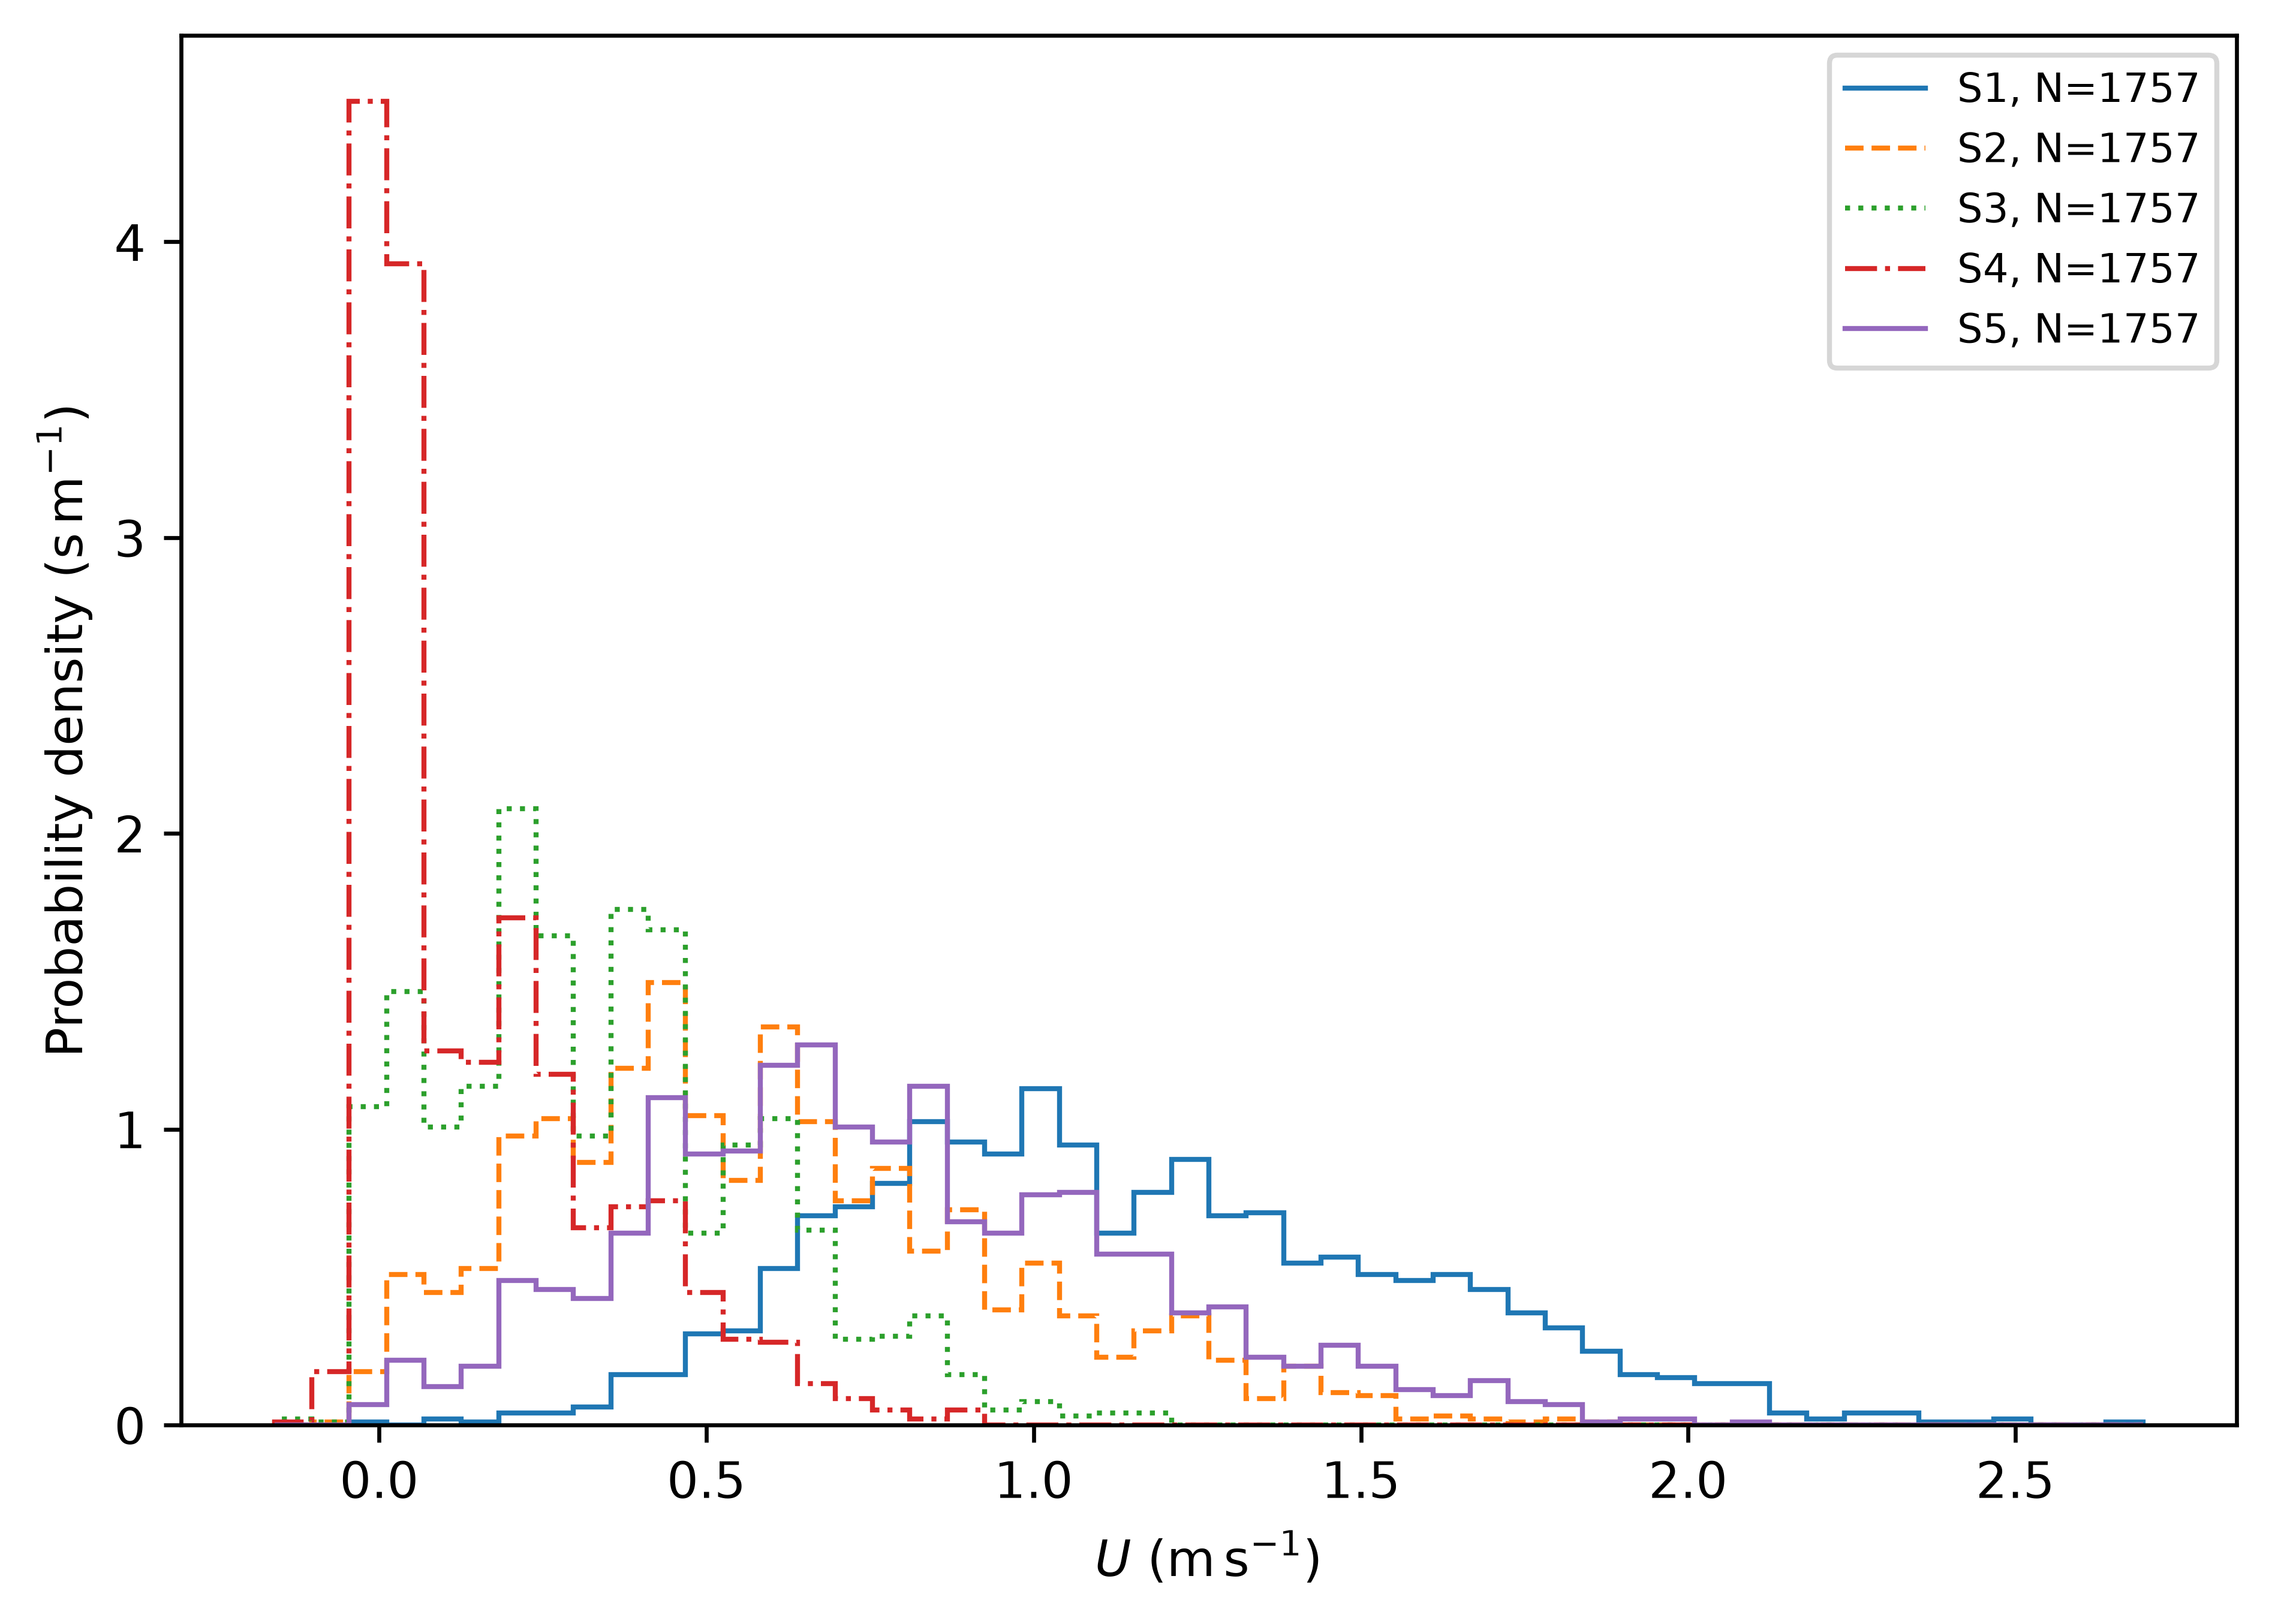

V_pdf


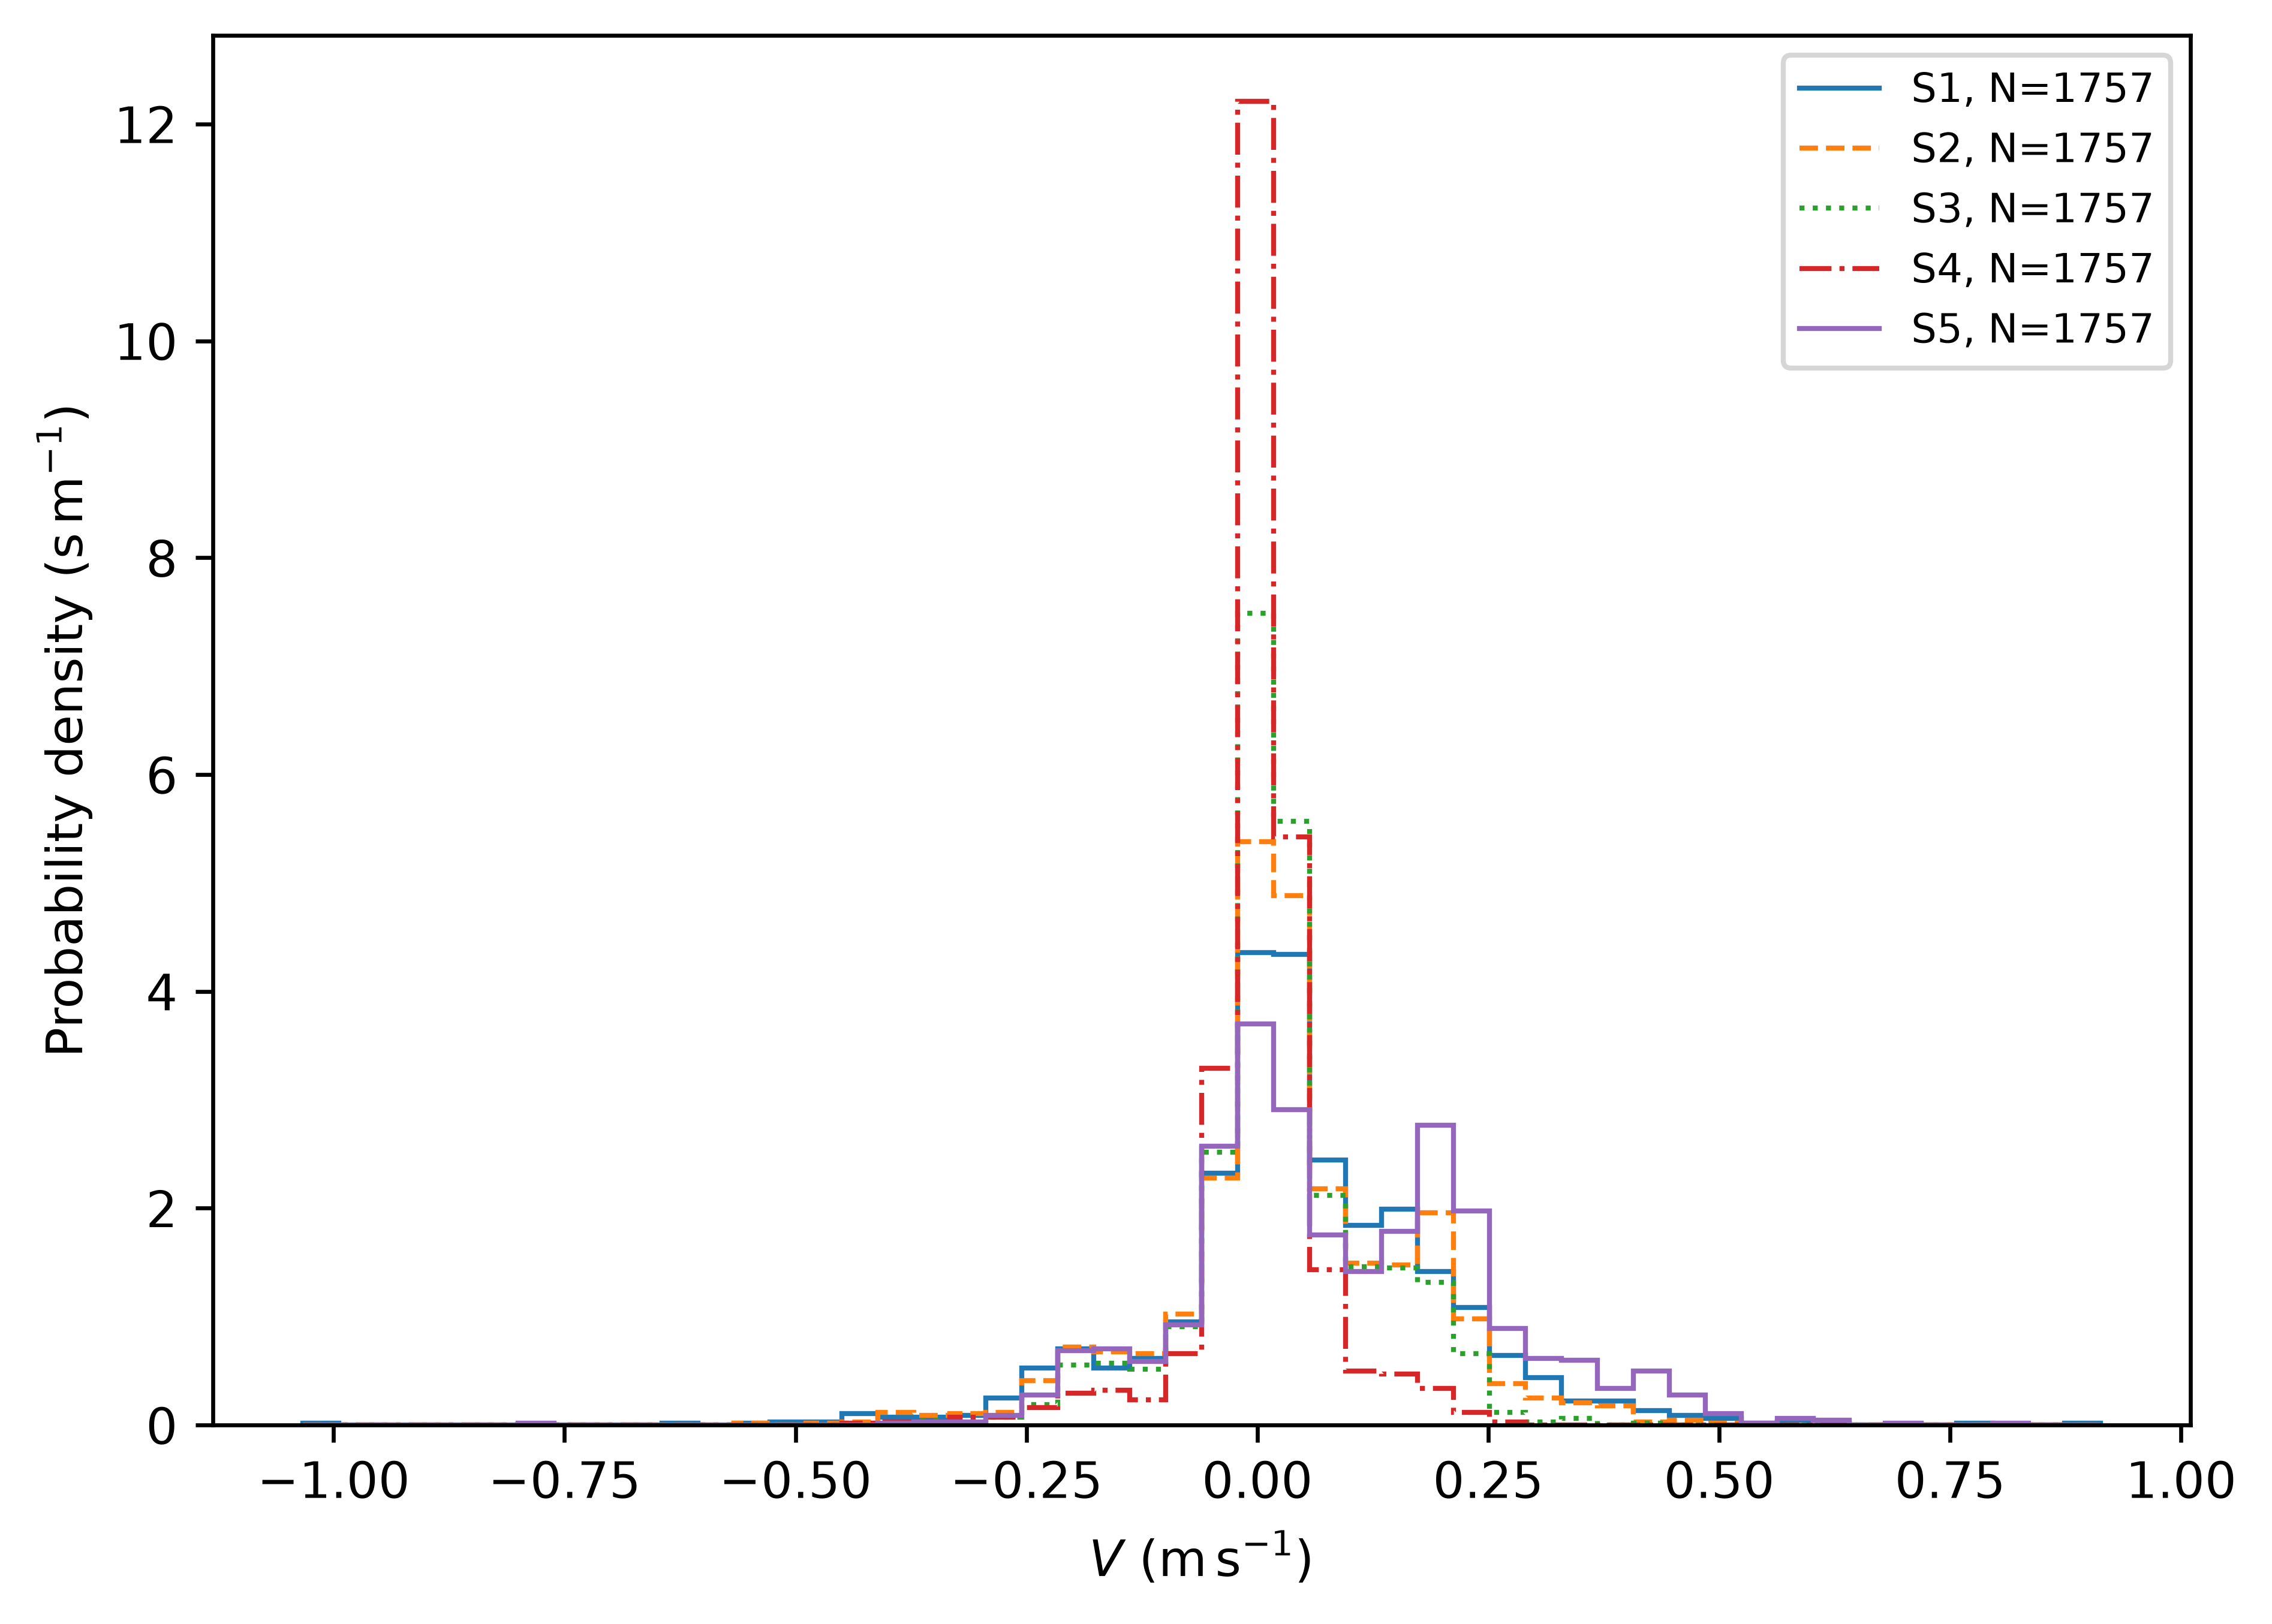

U_ecdf


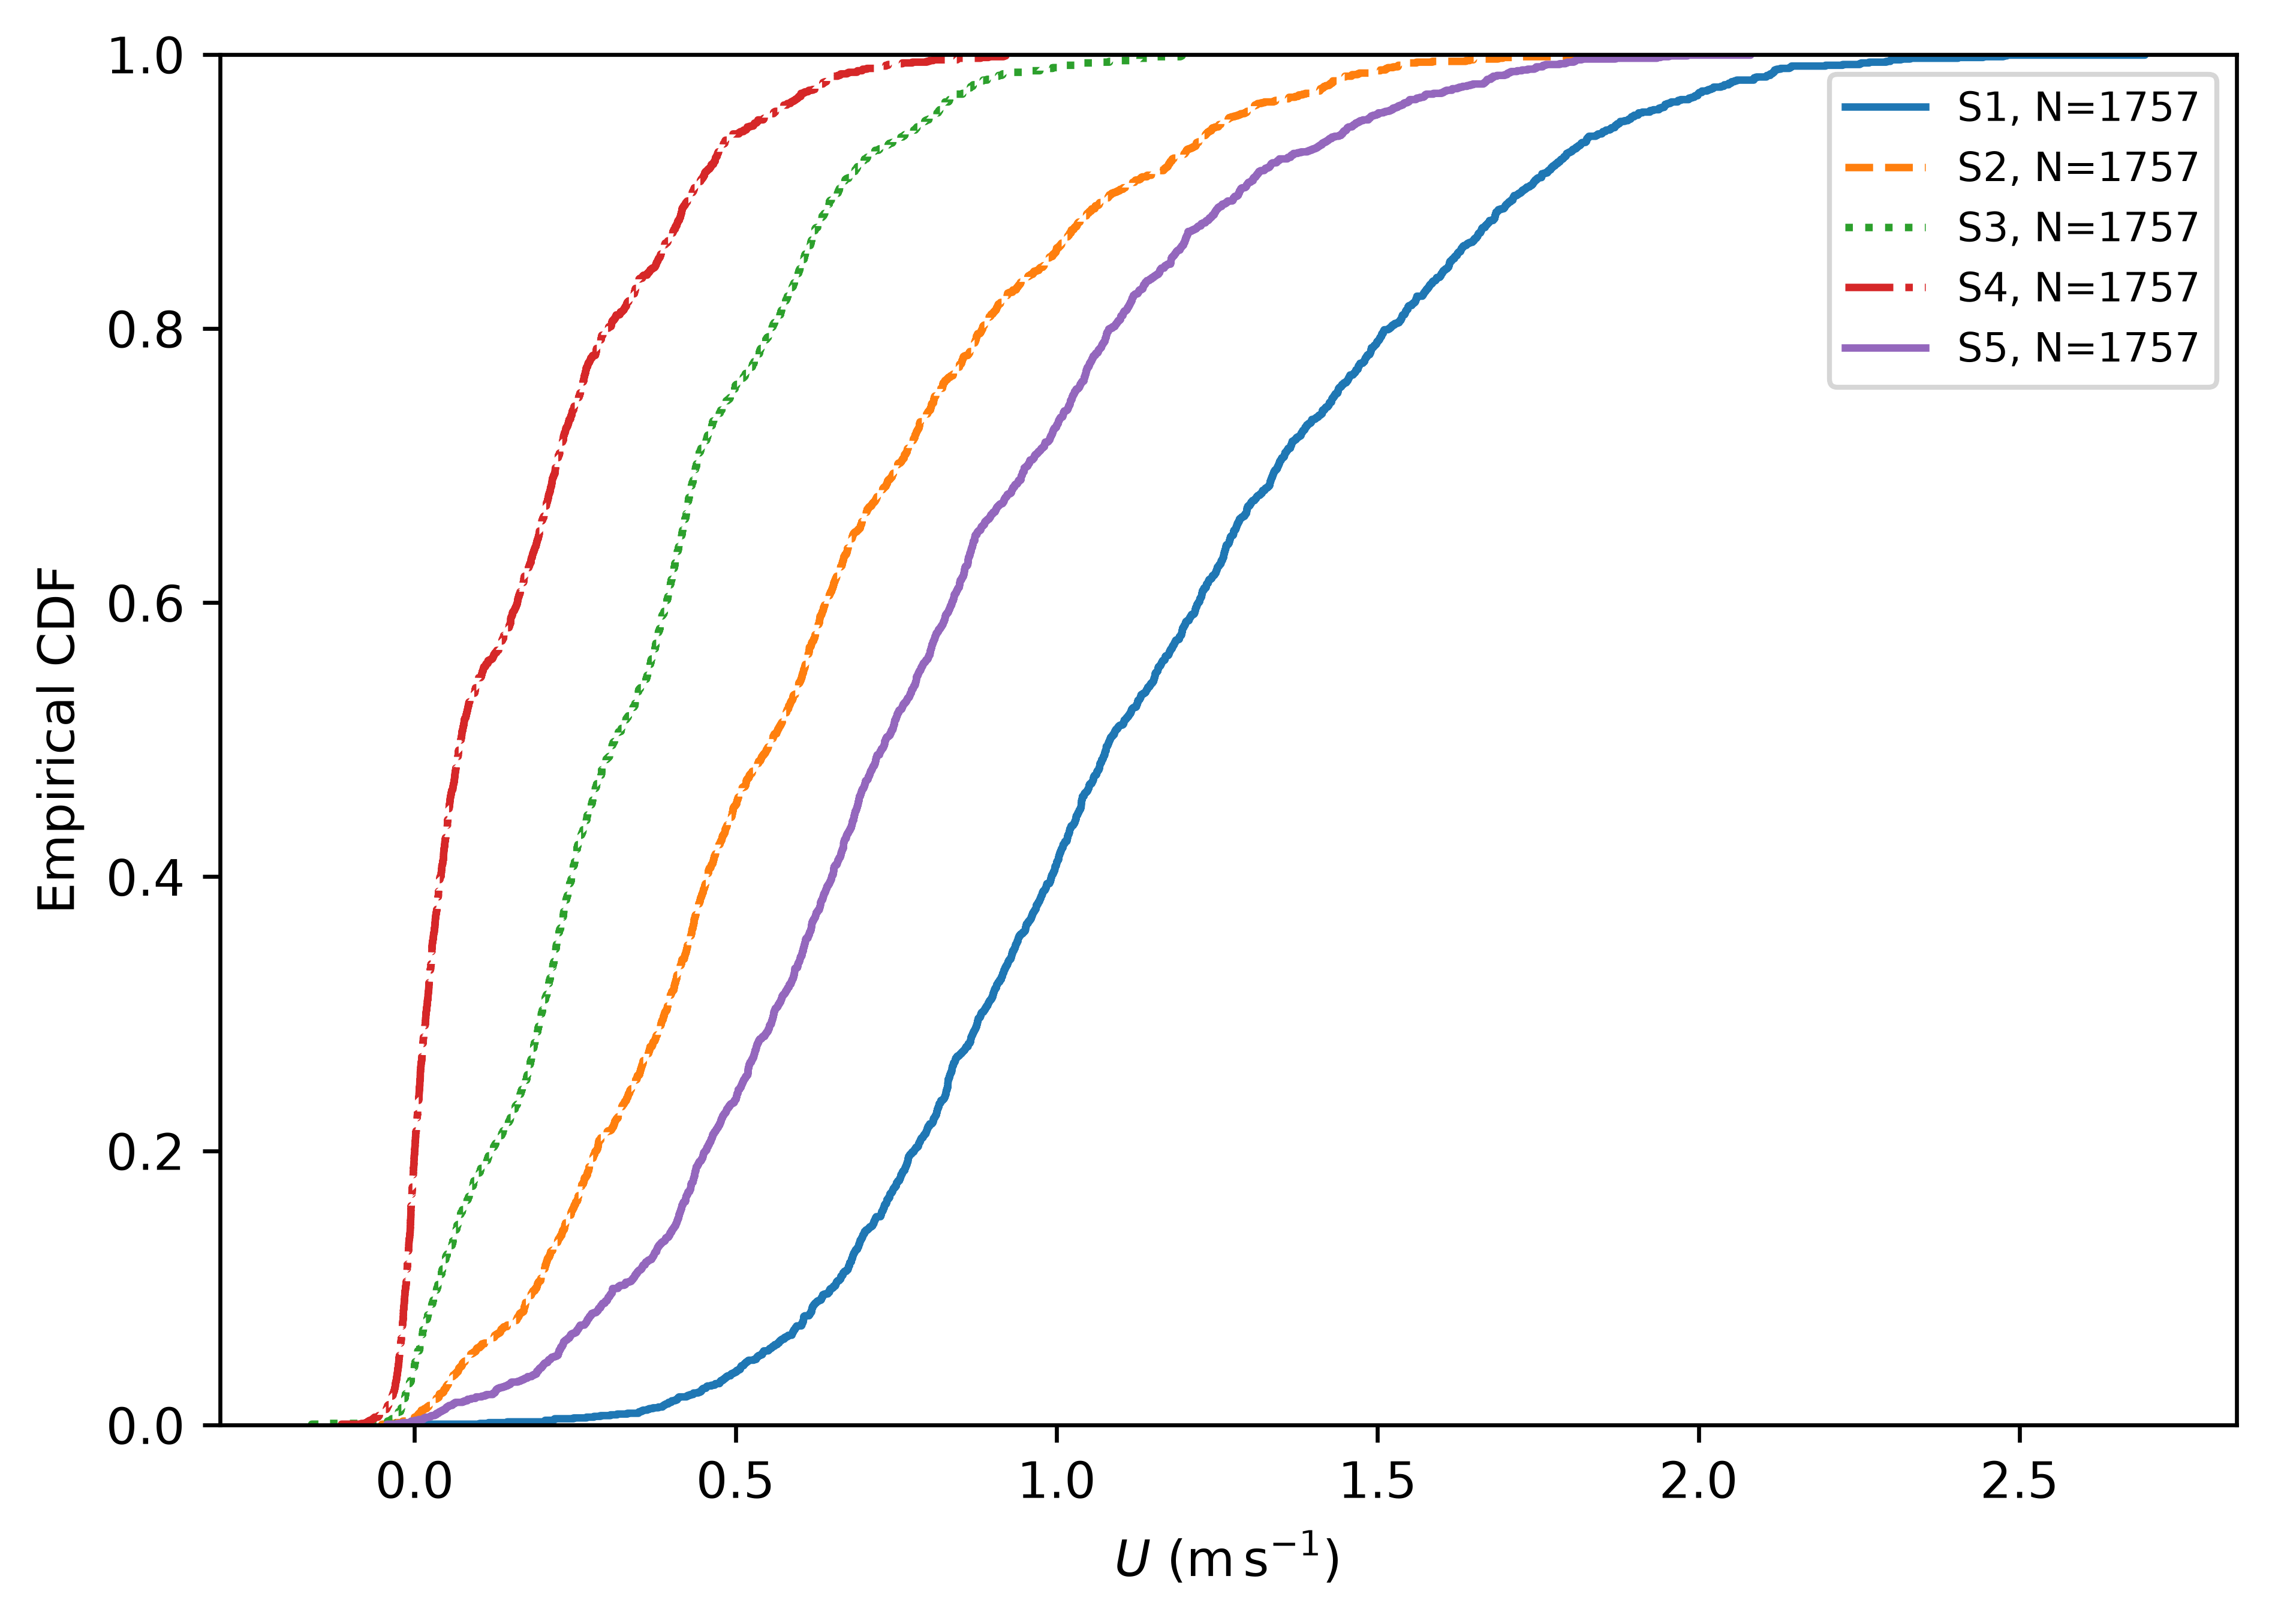

frame_879_quiver


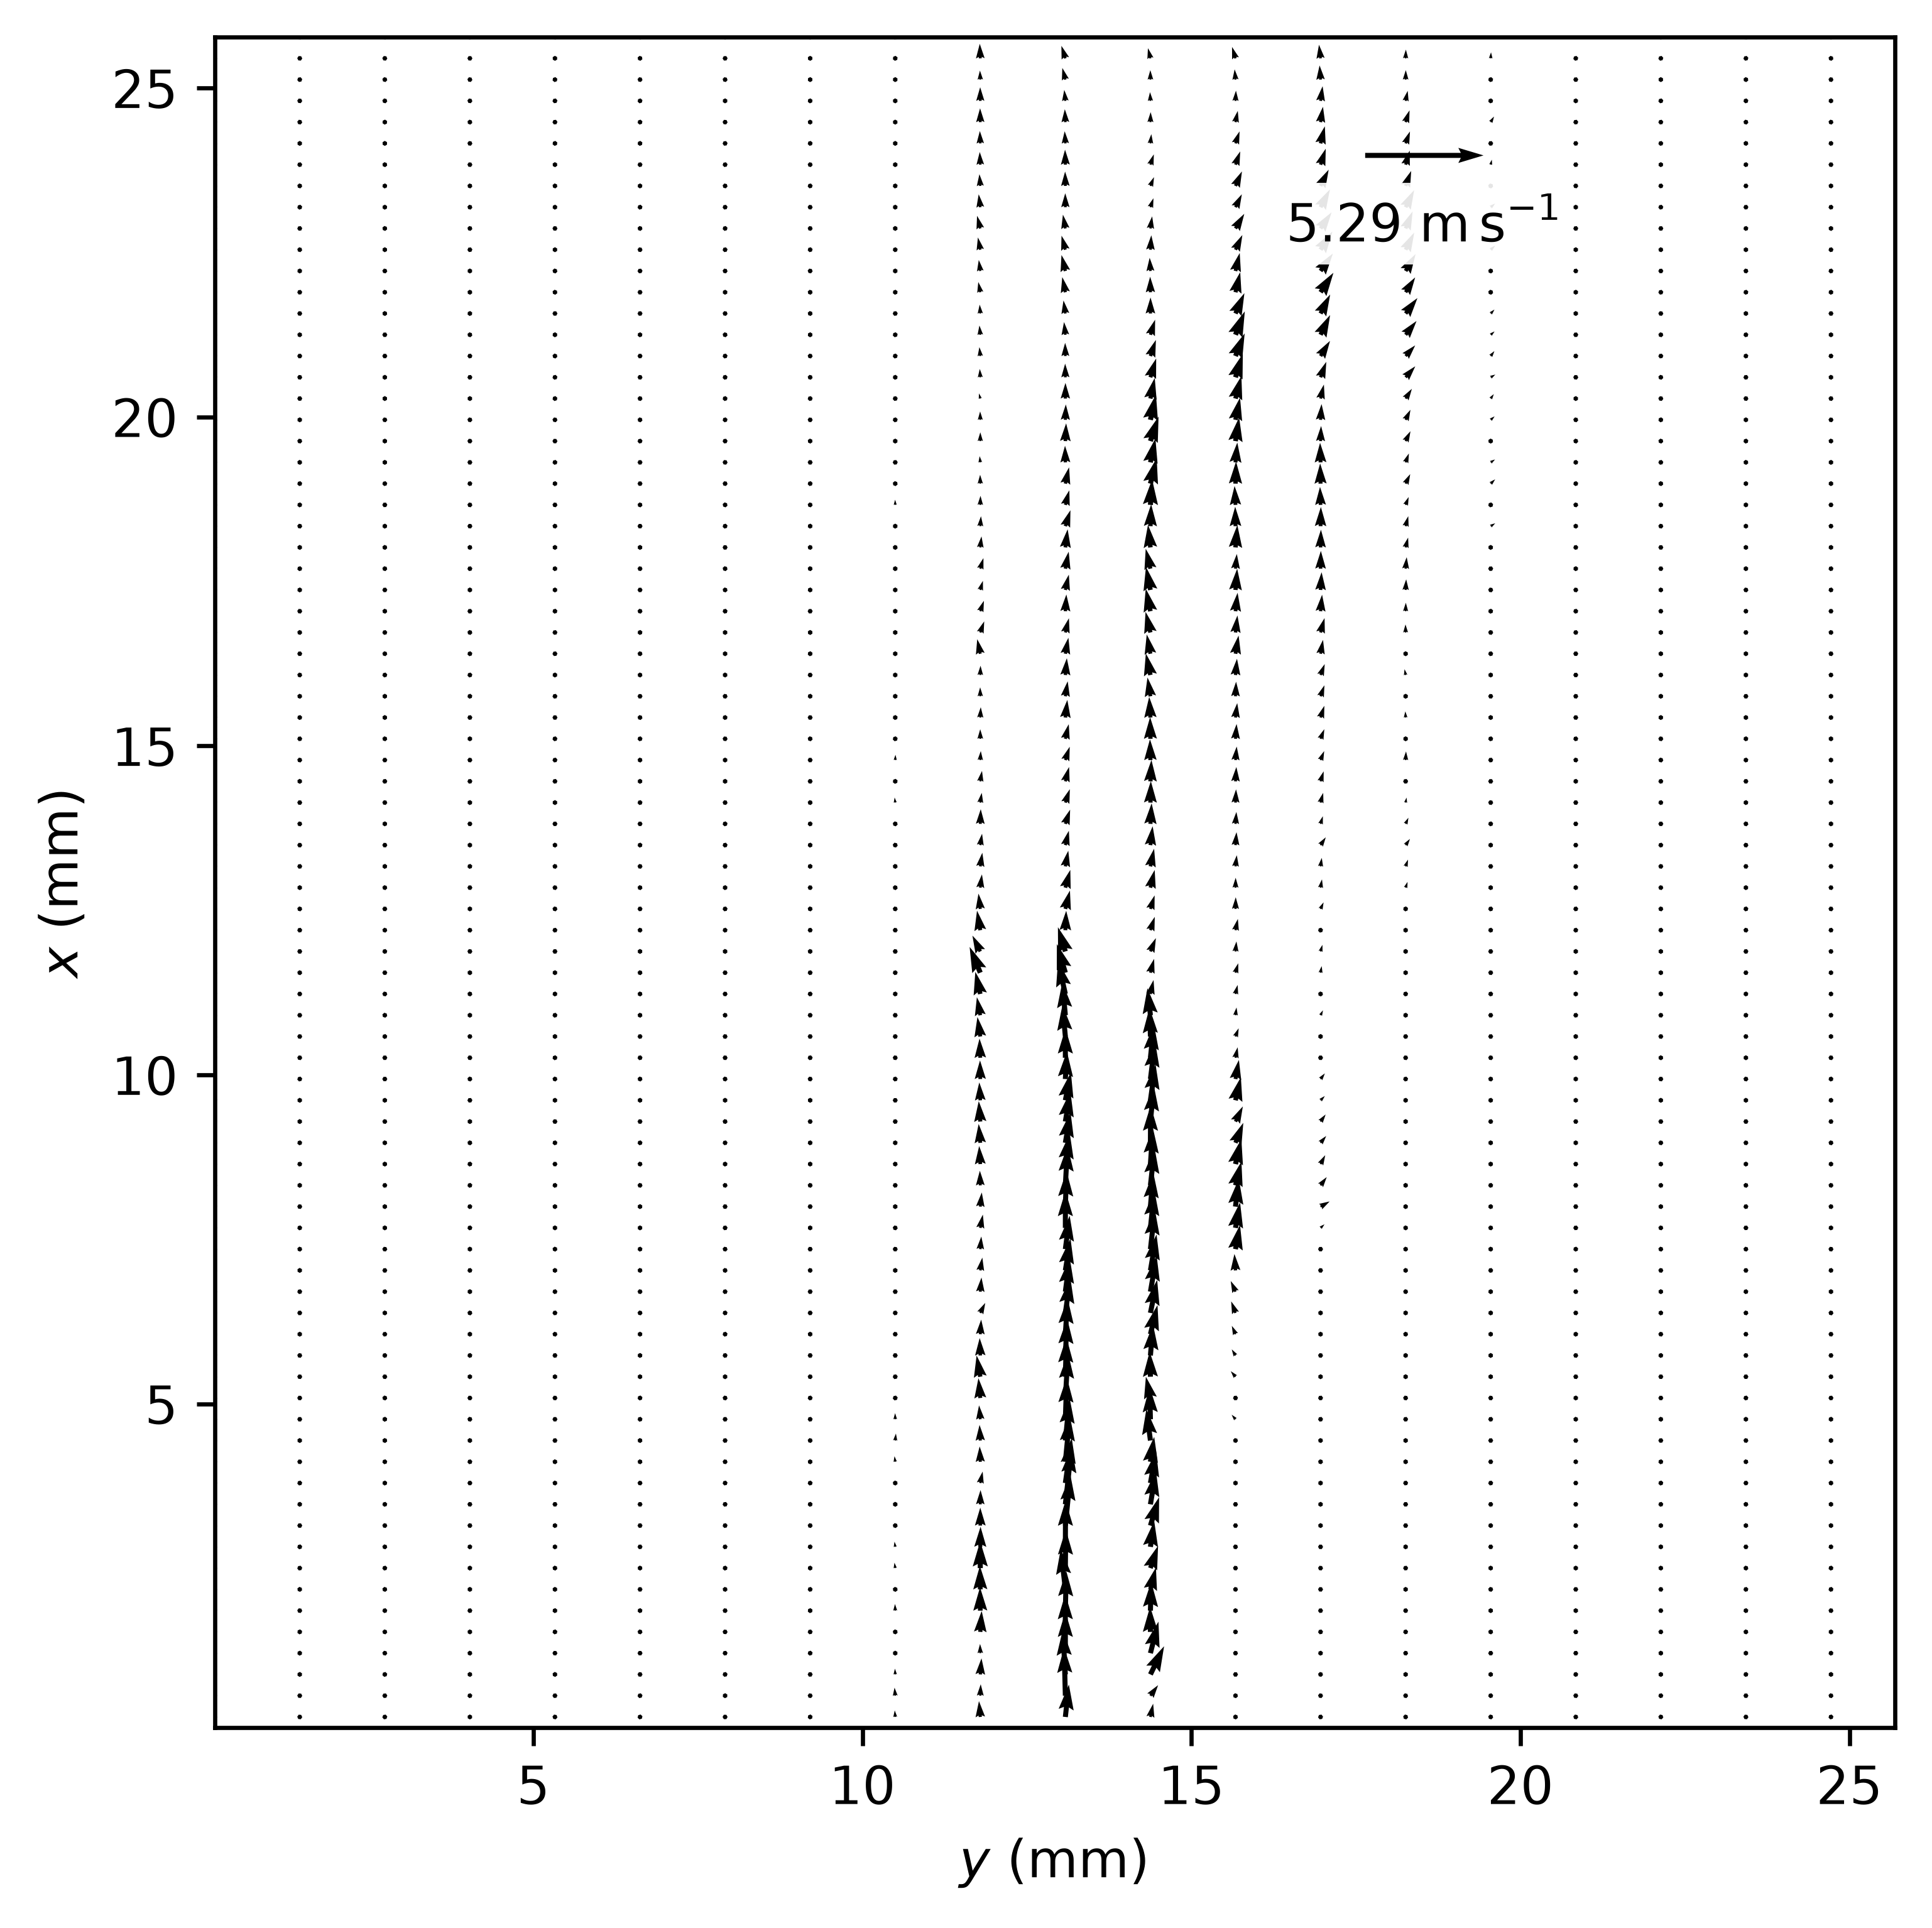

## Supplementary in-plane velocity magnitude

magnitude_mean_vector


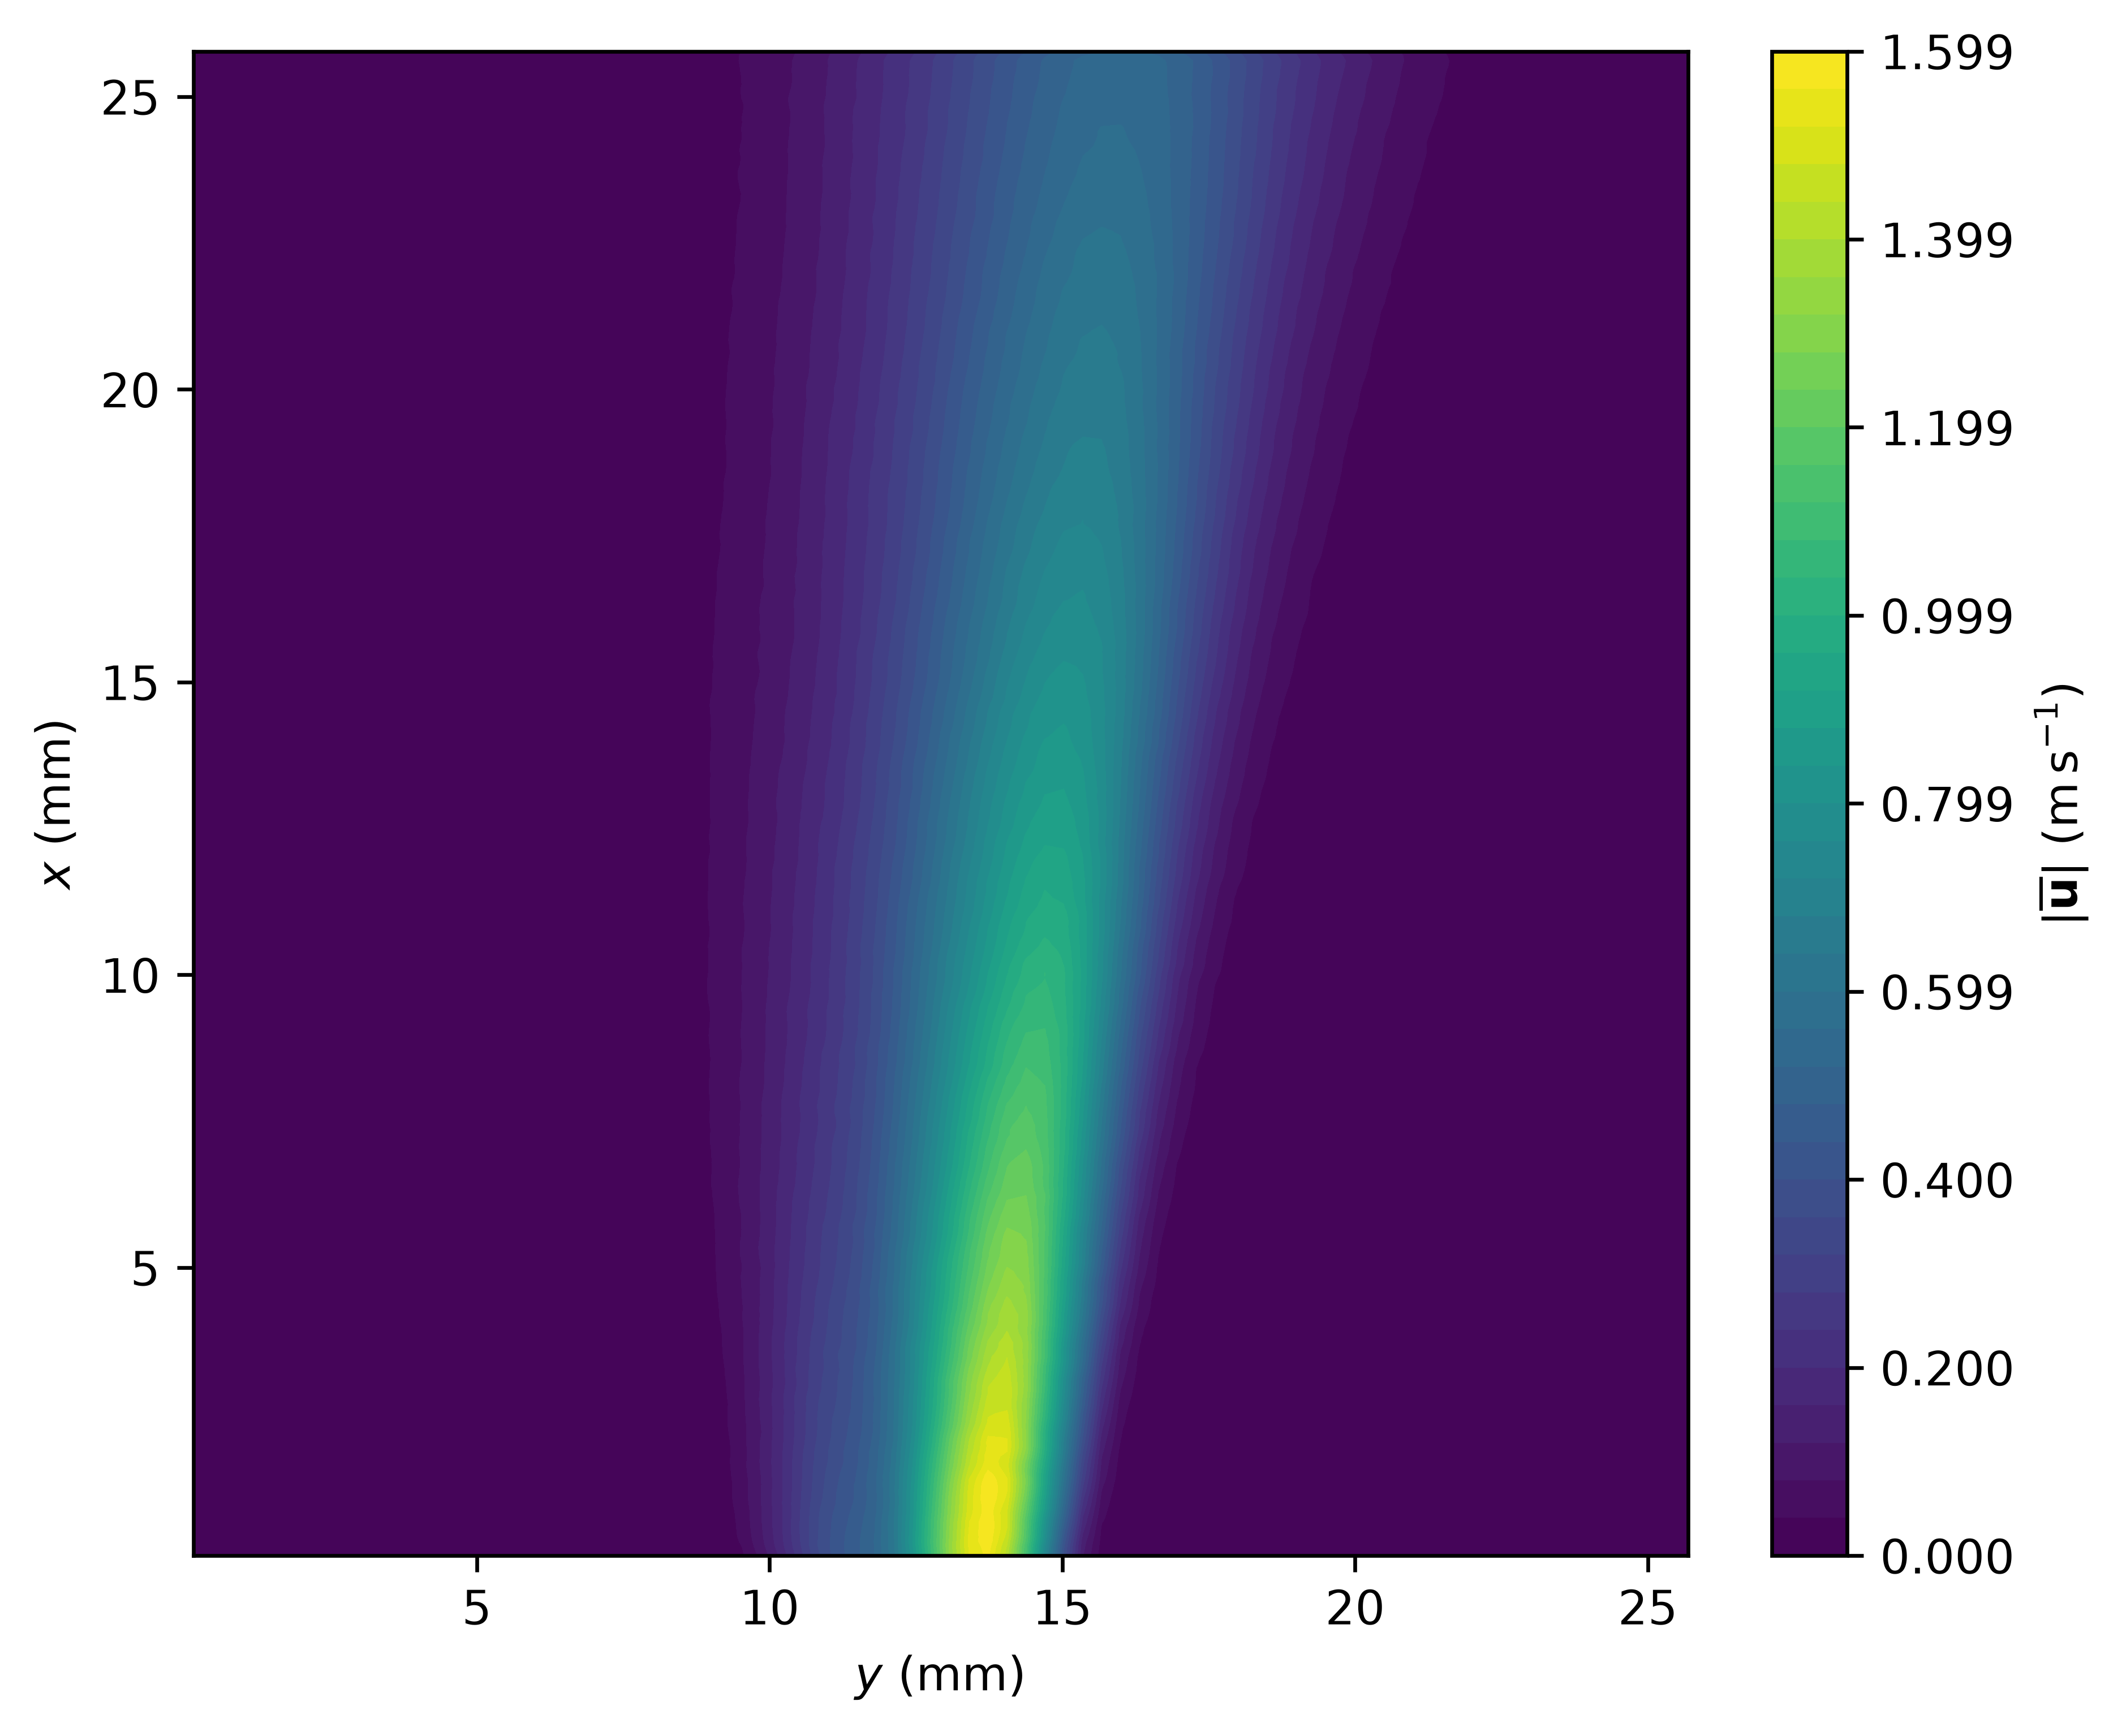

mean_instantaneous_velocity_magnitude


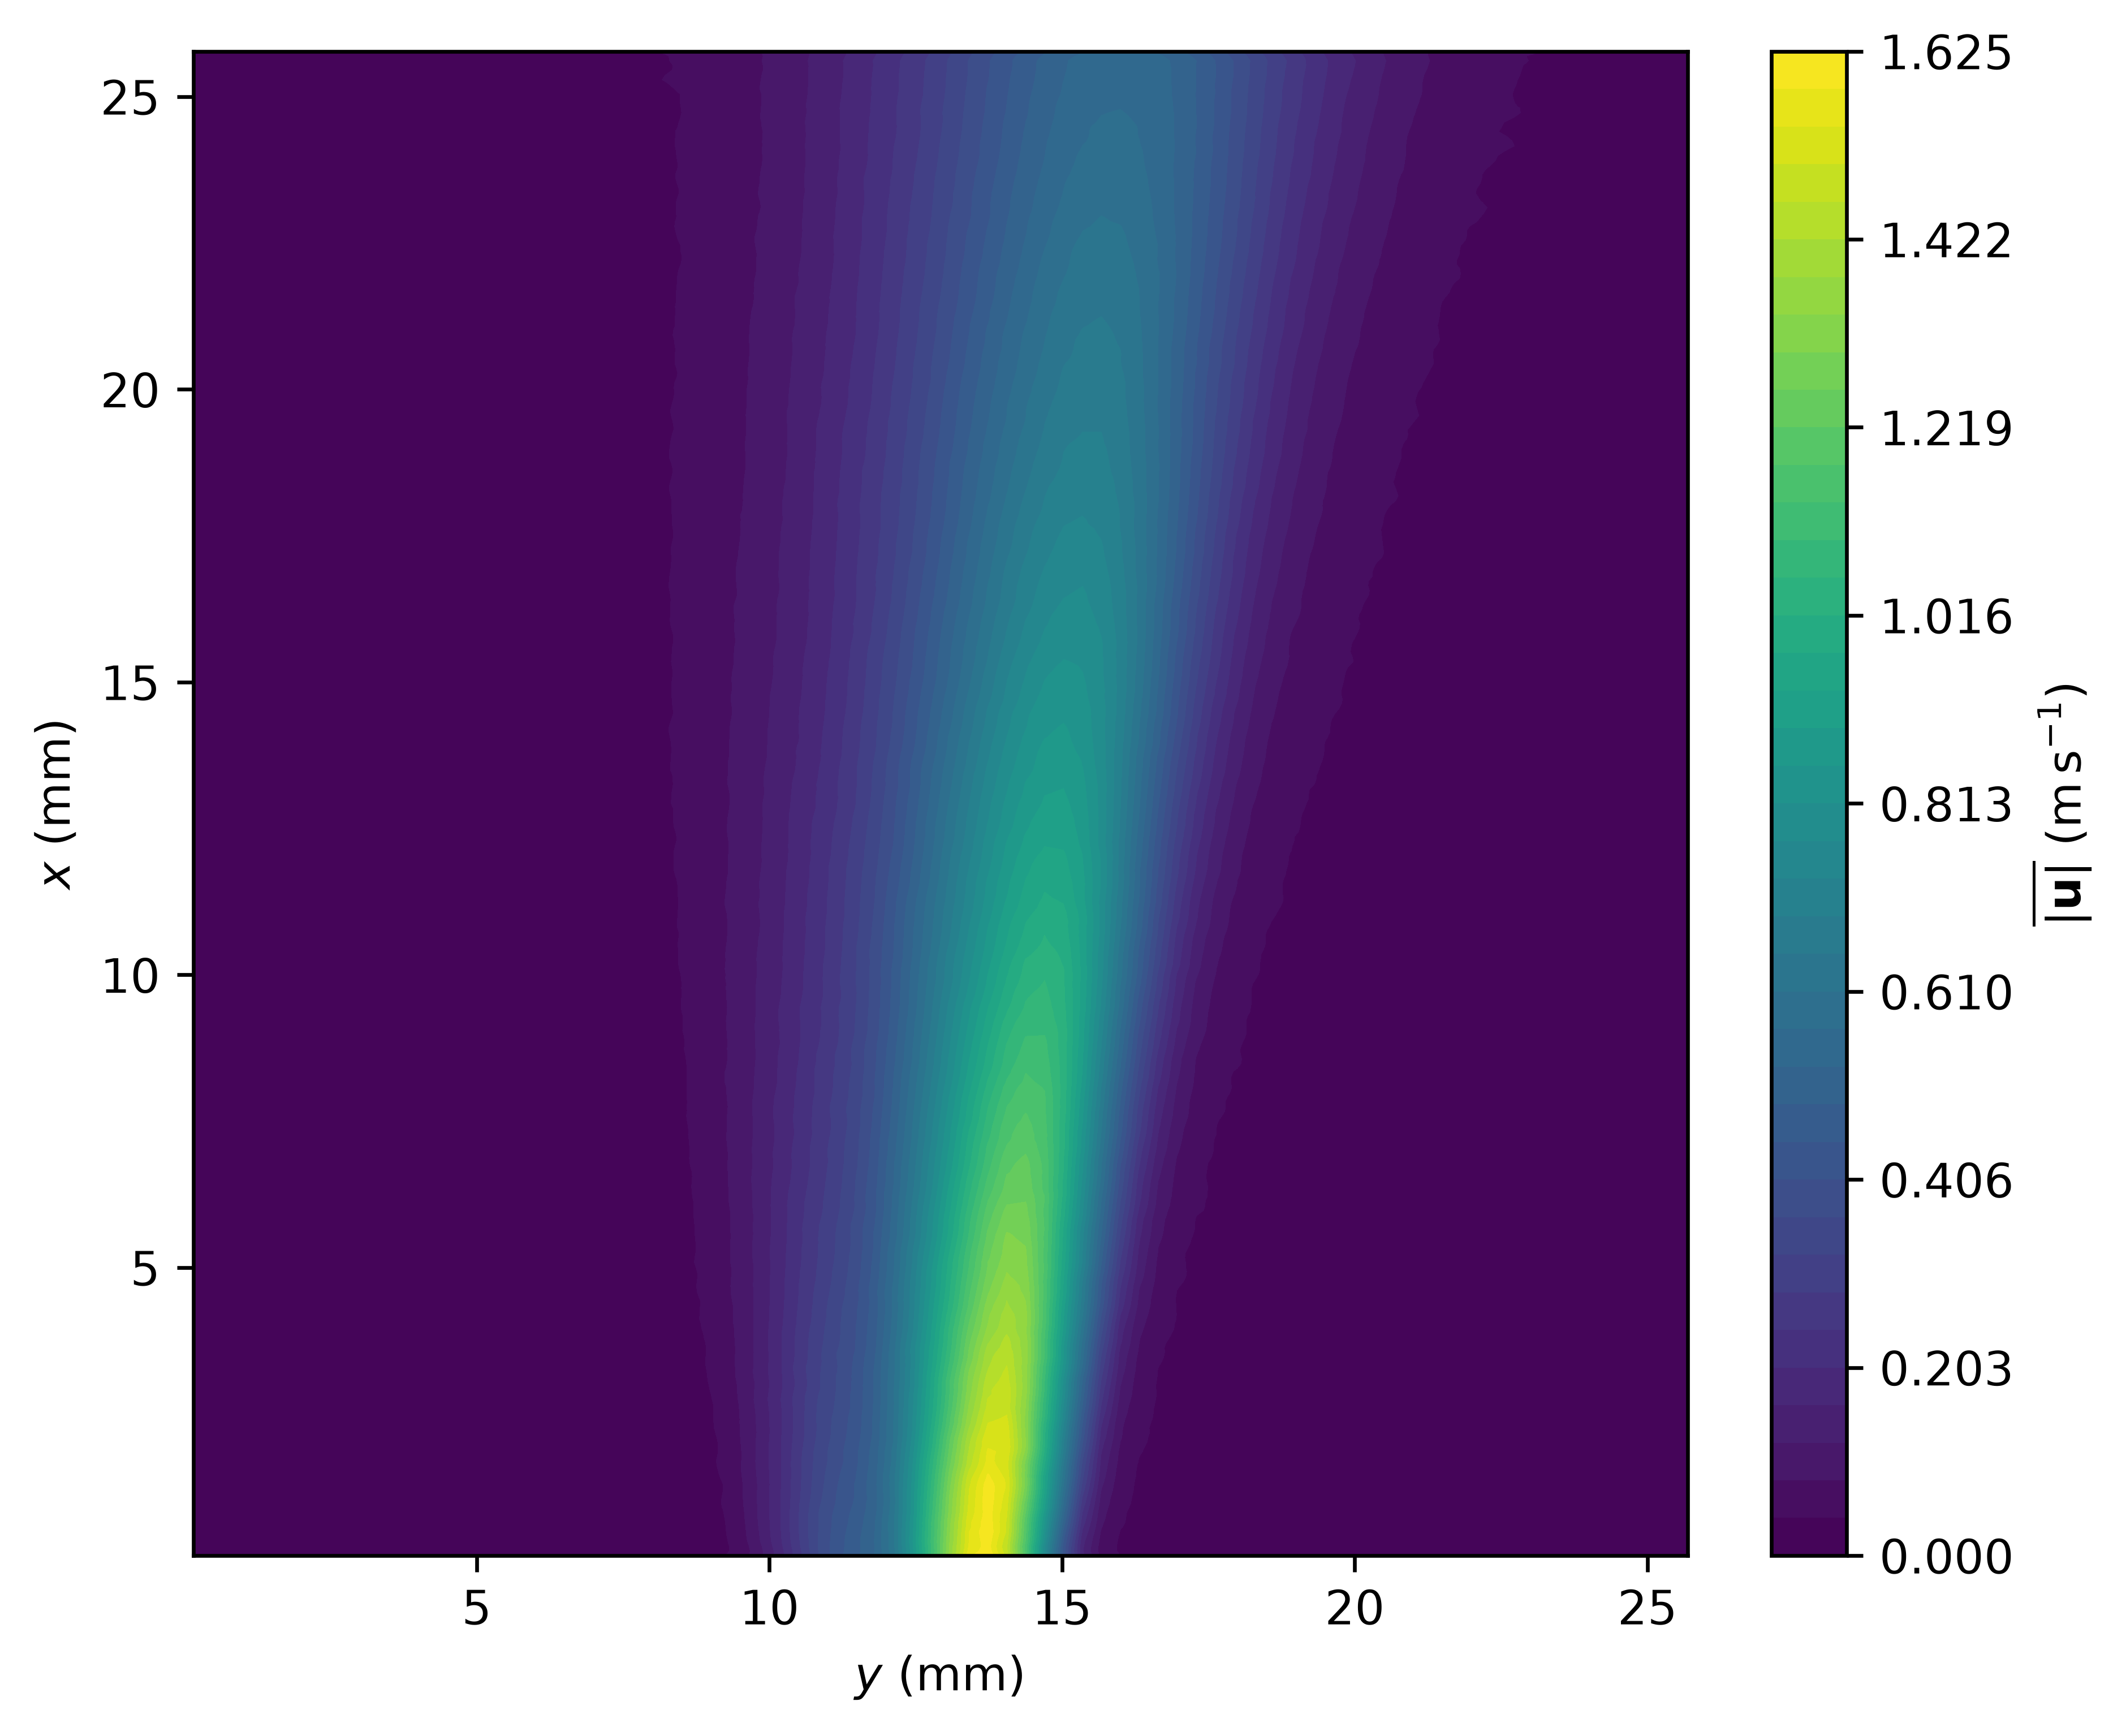

velocity_magnitude_pdf


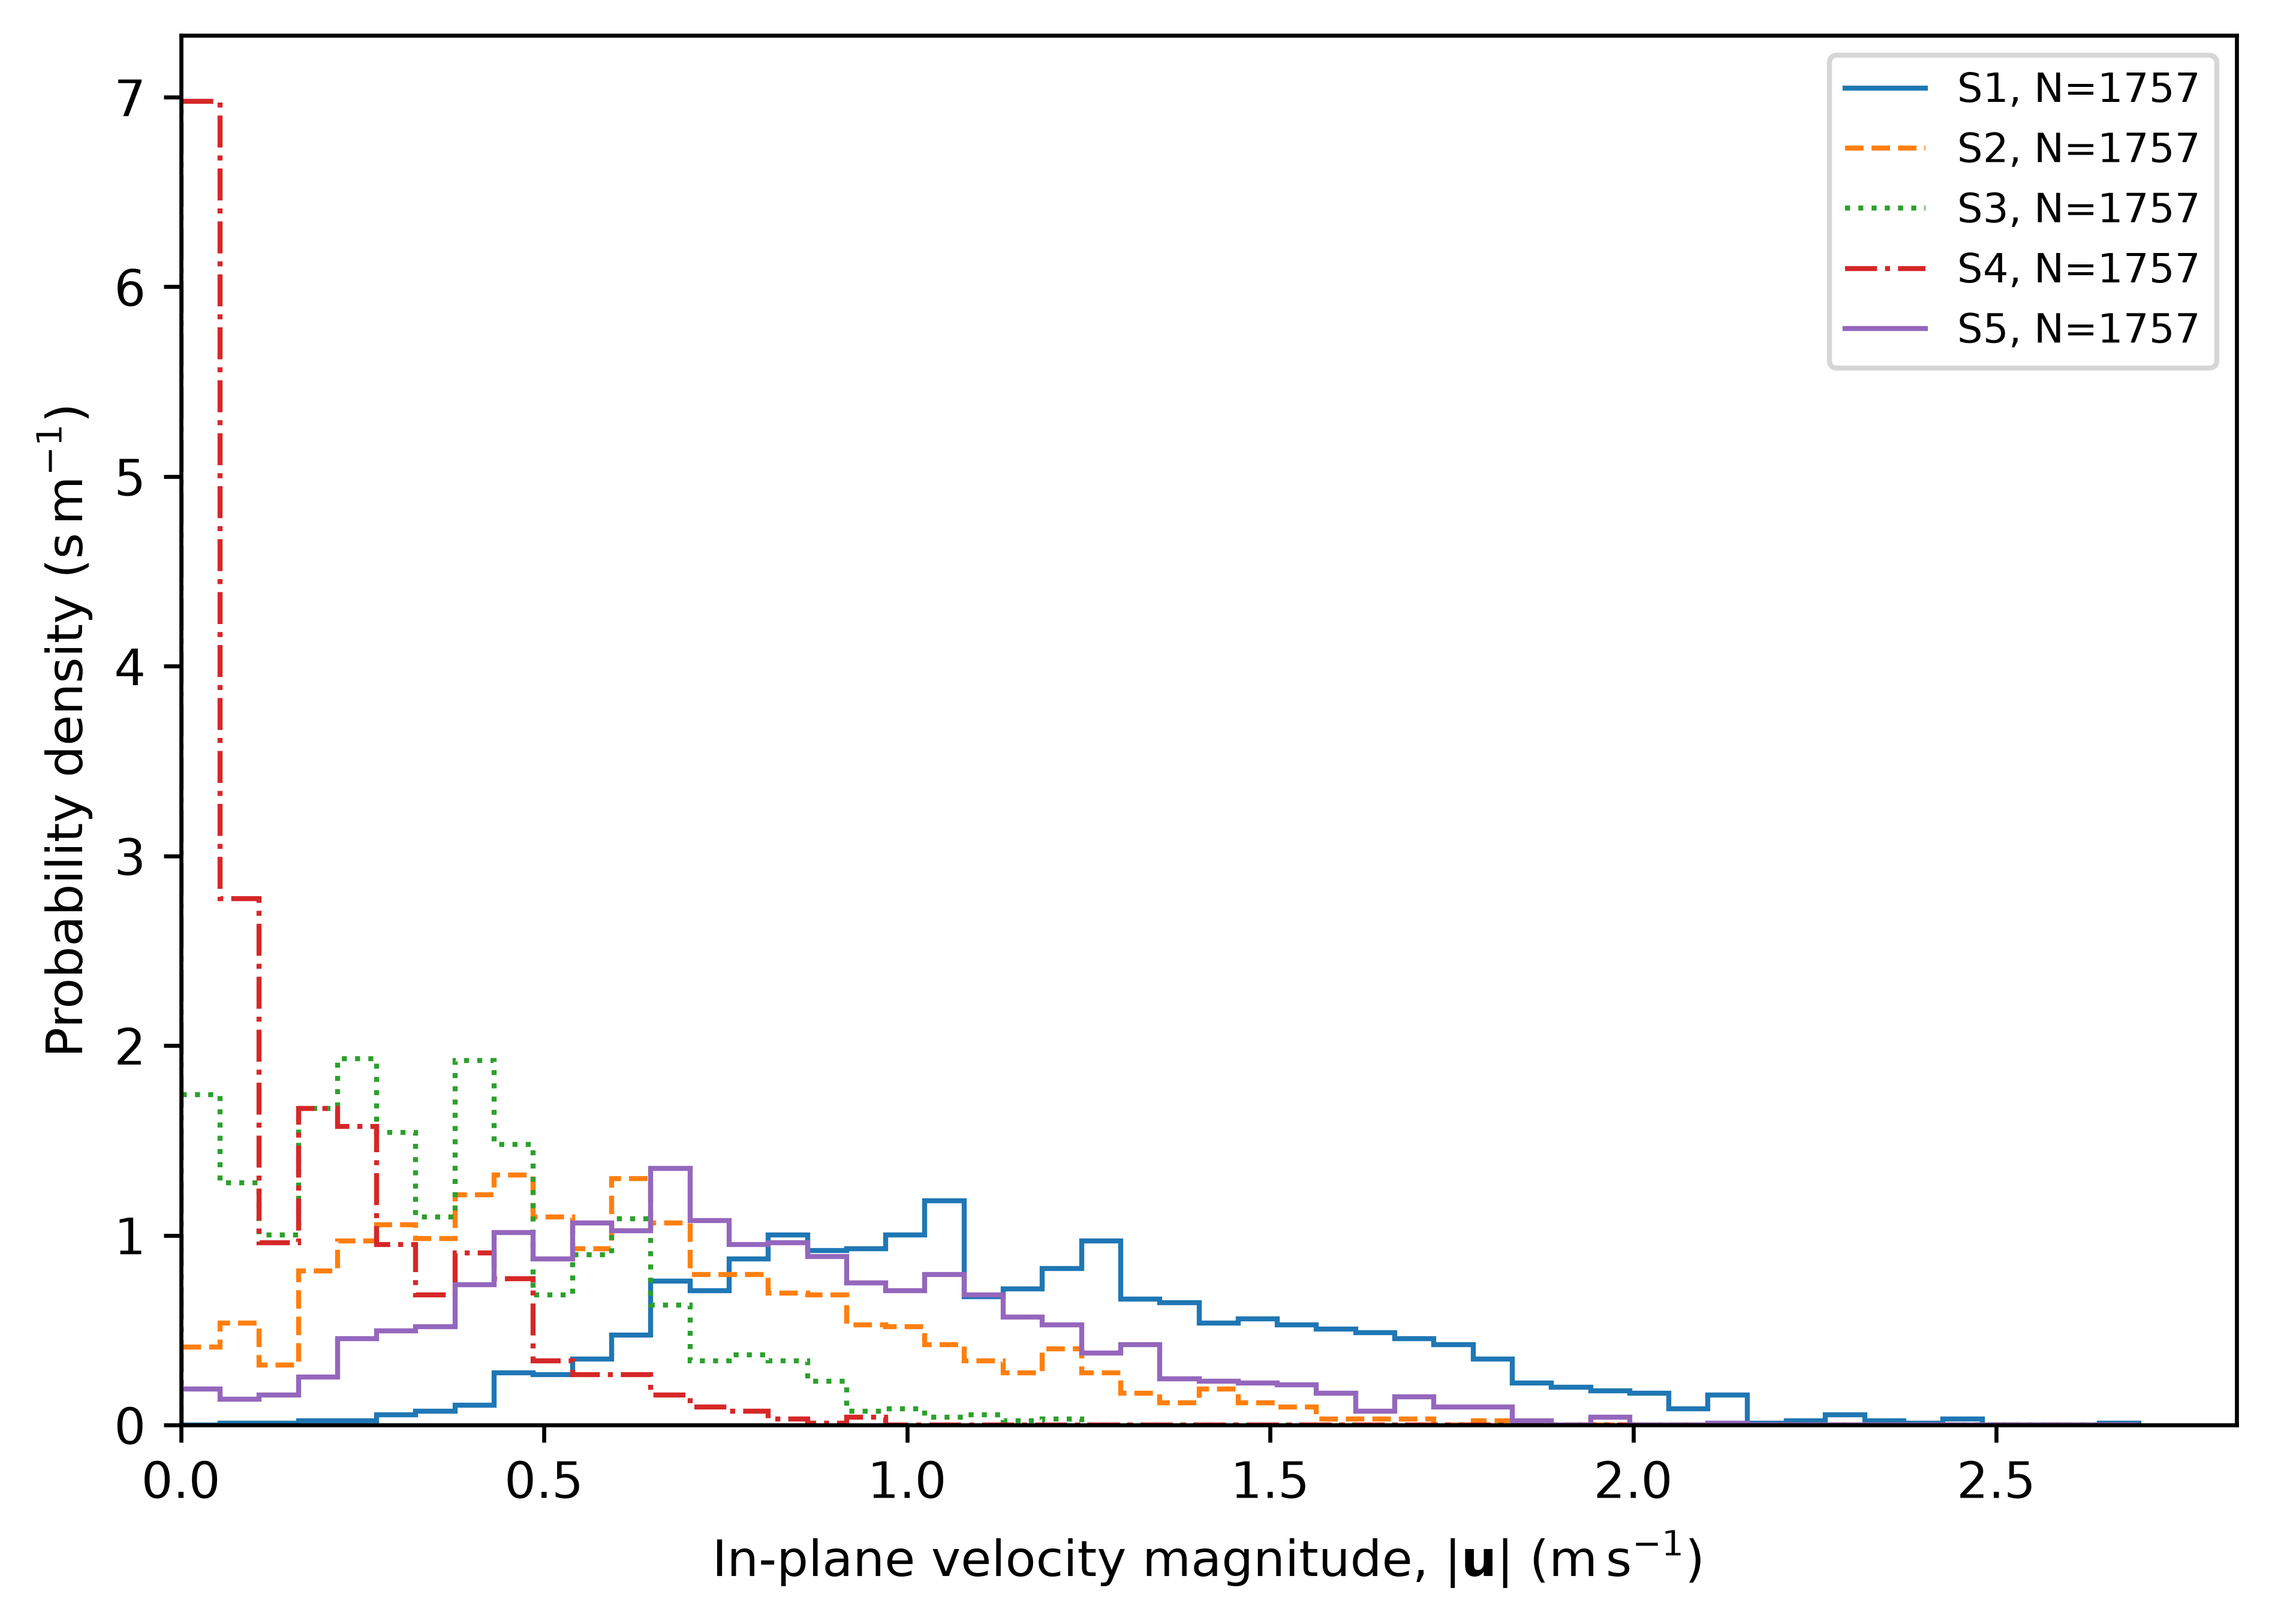

In [3]:
from IPython.display import Image, Markdown, display
display(Markdown((output/'METHODS.md').read_text(encoding='utf-8')))
for cid in results:
    folder=output/'figures'/cid
    display(Markdown('## Primary mean-component contours'))
    for name in config['primary_velocity_contours']:
        print(name)
        display(Image(filename=str(folder/(name+'.png')),width=600))
    display(Markdown('## Supporting component statistics'))
    for name in ['rms_U','rms_V','covariance','correlation','sampling_stations',
                 'profile_mean_U','profile_mean_V','profile_rms_U','U_pdf','V_pdf',
                 'U_ecdf',('frame_'+sorted(results[cid]['frames'],key=int)[len(results[cid]['frames'])//2]+'_quiver')]:
        print(name)
        display(Image(filename=str(folder/(name+'.png')),width=600))
    display(Markdown('## Supplementary in-plane velocity magnitude'))
    for name in config['supplementary_velocity_magnitude_figures']+['velocity_magnitude_pdf']:
        print(name)
        display(Image(filename=str(folder/(name+'.png')),width=600))


## Exact vectors for software comparison

All row/column indices are zero-based HDF5 array indices. Compare the same
numeric frame key and node in the processing software, including the displayed
coordinate reference and component units. These samples can test the 0.202
factor and retained vertical sign without inferring either from mean direction.


In [4]:
import csv
for cid in results:
    with (output/'results'/f'{cid}_vector_comparison.csv').open() as f:
        rows=list(csv.DictReader(f))
    columns=list(rows[0])
    table=[' | '.join(columns), ' | '.join(['---']*len(columns))]
    table += [' | '.join(str(row[c]) for c in columns) for row in rows]
    display(Markdown(chr(10).join(table)))
    with (output/'results'/f'{cid}_flag_sensitivity_summary.csv').open() as f:
        print(f.read())
    display(Markdown((output/'FINDINGS.md').read_text(encoding='utf-8')))
    print((output/'results/validation.json').read_text())


frame_key | row_zero_based | column_zero_based | exported_x | exported_y | axial_x_mm | transverse_y_mm | stored_us | stored_vs | axial_U_m_s | transverse_V_m_s | flag_code
--- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | ---
1 | 287 | 40 | 2591.0 | 512.0 | 2.5856 | 13.08455 | 0.4987640380859375 | 3.8663787841796875 | 0.781008514404297 | 0.10075033569335938 | 1
1 | 159 | 40 | 2591.0 | 2560.0 | 12.927999999999999 | 13.08455 | 1.2717132568359375 | 3.8921127319335938 | 0.786206771850586 | 0.2568860778808594 | 1
1 | 32 | 40 | 2591.0 | 4592.0 | 23.1896 | 13.08455 | 0.582421600818634 | 1.4049326181411743 | 0.28379638886451725 | 0.11764916336536409 | 1
879 | 287 | 40 | 2591.0 | 512.0 | 2.5856 | 13.08455 | 0.093841552734375 | 9.051025390625 | 1.82830712890625 | 0.018955993652343753 | 1
879 | 159 | 40 | 2591.0 | 2560.0 | 12.927999999999999 | 13.08455 | 0.9984893798828125 | 3.986347198486328 | 0.8052421340942383 | 0.20169485473632814 | 1
879 | 32 | 40 | 2591.0 | 4592.0 | 23.1896 | 13.08455 | -0.02629205584526062 | 3.080951452255249 | 0.6223521933555604 | -0.005310995280742646 | 1
1757 | 287 | 40 | 2591.0 | 512.0 | 2.5856 | 13.08455 | 0.660736083984375 | 3.685882568359375 | 0.7445482788085938 | 0.13346868896484376 | 1
1757 | 159 | 40 | 2591.0 | 2560.0 | 12.927999999999999 | 13.08455 | -0.10408401489257812 | 1.0812339782714844 | 0.21840926361083987 | -0.021024971008300784 | 1
1757 | 32 | 40 | 2591.0 | 4592.0 | 23.1896 | 13.08455 | -0.05423635244369507 | 0.2963275909423828 | 0.05985817337036133 | -0.010955743193626405 | 1

flag_code,total_finite_pairs,local_N_min,local_N_max,mean_U_min,mean_U_max,mean_U_max_abs_difference_from_all_pairs,mean_V_min,mean_V_max,mean_V_max_abs_difference_from_all_pairs,rms_U_min,rms_U_max,rms_U_max_abs_difference_from_all_pairs,rms_V_min,rms_V_max,rms_V_max_abs_difference_from_all_pairs
0,1097567,0,897,-0.536105167388916,1.6713828364096543,0.5269211656469904,-1.168764766573906,1.5772225705683234,1.5754941374572962,8.898565173149145e-05,0.899063946918237,0.8476223940466753,1.5939638018608077e-05,2.1126778564453126,2.038087509493784
1,43741073,860,1757,-0.021952845097176234,1.584827129445423,0.07150170364564157,-0.01676181079108398,0.17823646803412474,0.01389855302363166,0.011488667373521631,0.5814236892969032,0.1566401933919061,0.011560961381671116,0.2460737093546908,0.1386269772932633


# Provisional numerical findings

All numbers use the documented working assumptions, not independently verified exporter conventions.

## Batch4_Cam1

1757 fields; local finite-pair N=1757 to 1757.

| Quantity | Spatial minimum | Spatial maximum |
| --- | ---: | ---: |
| mean_U | -0.021815505 | 1.5919753 |
| mean_V | -0.017273836 | 0.17702743 |
| magnitude_mean_vector | 5.7478504e-05 | 1.5985397 |
| mean_instantaneous_velocity_magnitude | 0.016187069 | 1.6254535 |
| rms_U | 0.011488667 | 0.71820909 |
| rms_V | 0.011558675 | 0.3523175 |
| covariance | -0.01337018 | 0.059070284 |
| correlation | -0.93917838 | 0.92467577 |

Observed grid-node maximum mean U=1.5919753 m/s at axial x=1.212 mm, transverse y=13.73095 mm, row=304, column=42, N=1757. No outlet origin or global maximum outside measured support is claimed.

Flag-specific counts and mean/RMS differences are in flag_sensitivity_summary.csv and flag_station_comparison.csv; neither group is certified physically valid.


{
  "figure_count": 51,
  "formats_complete": true,
  "png_dpi": 600,
  "histogram_integrals": true,
  "color_ranges_cover_data": true,
  "csv_matches_fields": true,
  "station_checks": true,
  "stored_mean_checks": true,
  "flag_counts_partition_finite_pairs": true,
  "synthetic_reflection_covariance_check": true,
  "synthetic_coordinate_arrow_consistency": true
}

## Regenerating after software verification

Edit components, component_mapping, coordinate_mapping, transform, scales,
origin and working_assumptions in config/analysis.json. The plot basis is
[transverse V, axial U]. A common transform is applied to both positions and
velocities. An exporter-only component correction is distinct from a physical
basis change; record the evidence rather than reflecting coordinates twice.
Rerun this notebook to regenerate every result, including covariance, arrows,
profiles, station samples and the vector comparison sheet. No derivatives are
computed in this run. Configuration and methods are saved beside the results.
